# 04 — GP Correlated Errors (Models D and E, SPARC only)

**Project:** *Is the RAR Universal? Correlated-error-aware constraints on the scatter and acceleration scale of the radial acceleration relation in SPARC and independent HI samples*

## 1. Research Scope and Previous Model Verification

This notebook implements proposal Sections 4.2–4.4 for the correlated-error rungs of the error-model ladder:

* **Model D:** Model C (sampled D, i, Υ★; σ_int; τ) **plus** a radially correlated Gaussian-process term J_i K_i J_i.
* **Model E:** Model D with the **alternative nuisance prior** of Sec. 4.4(e), a wider Υ★ scatter. Nothing else changes.

The data are the same **153 SPARC galaxies and 3,164 likelihood points** as Notebook 03 Model C, with the same four documented positivity-rule exclusions. Notebook 03's Models A, B and C are read, never refitted or altered. The cross-survey gate did not pass, so the analysis is SPARC only.

**Not in this notebook:** injection–recovery (Notebook 06), population terms, survey offsets, cross-validation, any non-Bayesian ML.

**Labels:** `NB03` (results read from Notebook 03 files), `PILOT` (validation subset, not scientific), `FULL` (all 153 galaxies, opt-in), `REFERENCE` (published fixed values), `DERIVED` (diagnostics).

## 2. Environment Setup

In [1]:
import os, sys, importlib.util, subprocess
N_CPU = os.cpu_count() or 1
os.environ["XLA_FLAGS"] = f"--xla_force_host_platform_device_count={max(1, min(N_CPU, 8))}"
IN_COLAB = "google.colab" in sys.modules
REQUIRED = {"jax": "jax", "numpyro": "numpyro", "xarray": "xarray", "h5netcdf": "h5netcdf", "h5py": "h5py",
            "scipy": "scipy", "matplotlib": "matplotlib", "pandas": "pandas"}
missing = [p for m, p in REQUIRED.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import re, json, time, glob, hashlib, logging, platform, warnings, resource, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd, scipy, scipy.stats as sst, xarray as xr
import matplotlib, matplotlib.pyplot as plt
import jax, jax.numpy as jnp
from jax.scipy.linalg import cholesky as jcholesky, solve_triangular
import numpyro, numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value
from numpyro.diagnostics import split_gelman_rubin, effective_sample_size
numpyro.enable_x64()
numpyro.set_host_device_count(max(1, min(N_CPU, 8)))

RUN_TIMESTAMP = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
RUN_ID = dt.datetime.now(dt.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
            "jax": jax.__version__, "numpyro": numpyro.__version__, "xarray": xr.__version__, "matplotlib": matplotlib.__version__,
            "cpu_count": N_CPU, "jax_devices": len(jax.devices()), "jax_backend": jax.default_backend(), "x64": bool(jax.config.read("jax_enable_x64"))}
print(f"Run {RUN_ID} | Colab: {IN_COLAB}"); print(VERSIONS)

Run 20261022T124247Z | Colab: True
{'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'jax': '0.11.1', 'numpyro': '0.22.0', 'xarray': '2025.12.0', 'matplotlib': '3.10.0', 'cpu_count': 2, 'jax_devices': 2, 'jax_backend': 'cpu', 'x64': True}


In [2]:
# =====================================================================
# CONFIGURATION — paths, GP settings, priors, sampler, stages
# =====================================================================
DRIVE_MOUNT_POINT = Path("/content/drive"); DRIVE_ROOT = DRIVE_MOUNT_POINT / "MyDrive"
PROJECT_ROOT = Path(os.environ.get("RAR_PROJECT_ROOT", str(DRIVE_ROOT / "RAR_Universality_Research")))
ROTMOD_DIR = PROJECT_ROOT / "01_Datasets" / "SPARC" / "Rotmod_LTG"
PROC = PROJECT_ROOT / "03_Processed_Data"
DIRS = {"processed": PROC, "models": PROJECT_ROOT / "04_Trained_Models", "tables": PROJECT_ROOT / "05_Results" / "Tables",
        "graphs": PROJECT_ROOT / "05_Results" / "Graphs", "posterior": PROJECT_ROOT / "05_Results" / "Posterior_Samples",
        "diagnostics": PROJECT_ROOT / "05_Results" / "Diagnostics", "logs": PROC / "logs"}
NB02 = {"points": PROC / "sparc_rar_points_baseline.csv", "galaxies": PROC / "sparc_rar_galaxies_baseline.csv",
        "npz": PROC / "sparc_rar_model_inputs.npz"}
NB03_RUN_ID = os.environ.get("RAR_NB03_RUN_ID", "")     # leave "" to pick the latest Notebook 03 run with a completed full Model C

KPC_IN_M, KMS_IN_MS, LN10 = 3.0856775814913673e19, 1.0e3, float(np.log(10.0))
REF = {"a0": 1.20e-10, "beta": 0.5, "upsilon_disk": 0.5, "upsilon_bulge": 0.7}

# ---------------- GP specification (proposal Sec. 4.2-4.3) ----------------
GP = {
    "kernel": "SE",            # squared-exponential (proposal); "M32" = Matern-3/2 is run as a pilot sensitivity variant
    "pooling": "partial",      # hierarchical: per-galaxy A_i, l_i drawn from population distributions; "complete" = one global A and u
    "mode": "additive",        # K is an ADDITIONAL correlated component on top of the published diagonal errors;
                               # "decomposition" splits the published variance into correlated (phi) and independent (1 - phi) parts
    "lmin_mult": 1.0,          # l_min,i = lmin_mult x median radial spacing of galaxy i (no beam sizes available for SPARC)
    "lmax_frac": 0.5,          # l_max,i = lmax_frac x radial extent (R_max - R_min) of galaxy i
    "jitter_dex2": 0.0,        # diagonal regularisation; 0 unless the covariance checks show it is needed (then reported)
}
BOUND_VARIANTS = {"base": (1.0, 0.5), "narrow": (1.0, 0.25), "wide": (0.5, 1.0)}

# Shared priors: identical to Notebook 03 (verified against its saved configuration in Section 4)
UPS_SIGMA_DEX = {"D": 0.10, "E": 0.20}   # Model E: wider Upsilon* scatter = the alternative nuisance prior of Sec. 4.4(e)
GP_PRIORS = {
    "mu_lnA":    {"dist": "Normal", "loc": float(np.log(5.0)), "scale": 1.0, "unit": "ln(km/s)",
                  "note": "population median amplitude; 95% prior range ~0.7-35 km/s, broad enough to include amplitudes reported as upper limits "
                          "by Chase et al. 2025 (~20 km/s) and Oman & Riley 2024 (<10 km/s, Milky Way). A choice, not a measurement."},
    "sigma_lnA": {"dist": "HalfNormal", "scale": 0.5, "unit": "ln(km/s)", "note": "galaxy-to-galaxy spread of ln A; regularisation choice"},
    "mu_u":      {"dist": "Normal", "loc": 0.0, "scale": 1.5, "unit": "logit", "note": "population position of ln l between each galaxy's bounds"},
    "sigma_u":   {"dist": "HalfNormal", "scale": 1.0, "unit": "logit", "note": "galaxy-to-galaxy spread; regularisation choice"},
    "phi":       {"dist": "Uniform", "low": 0.0, "high": 1.0, "unit": "-", "note": "decomposition variant only: correlated fraction of published variance"},
}

# ---------------- Sampler and stages ----------------
SEED = 20261023
TARGET_ACCEPT, MAX_TREE_DEPTH = 0.90, 10
PILOT = {"chains": int(os.environ.get("RAR_CHAINS", 4)), "warmup": int(os.environ.get("RAR_PILOT_WARMUP", 1000)),
         "samples": int(os.environ.get("RAR_PILOT_SAMPLES", 1000))}
PILOT_VARIANTS = ["D_base", "D_bounds_narrow", "D_bounds_wide", "D_matern32", "D_complete_pooling", "D_decomposition", "E_base"]
RUN_FULL = os.environ.get("RAR_FULL_RUN", "0") == "1"              # <-- enable in Section 14 only after the pilot passes
FORCE_FULL_DESPITE_PILOT = os.environ.get("RAR_FORCE_FULL", "0") == "1"   # leave False; any override must be reported
FULL = {"models": ["D", "E"], "chains": int(os.environ.get("RAR_CHAINS", 4)),
        "warmup": int(os.environ.get("RAR_FULL_WARMUP", 1500)), "samples": int(os.environ.get("RAR_FULL_SAMPLES", 1000))}
ALLOW_OVERWRITE = False

RHAT_MAX, ESS_BULK_MIN, ESS_TAIL_MIN, DIVERGENCES_MAX = 1.01, 400, 400, 0
ILOO = {"post_draws": int(os.environ.get("RAR_ILOO_DRAWS", 400)), "mc": int(os.environ.get("RAR_ILOO_MC", 64))}   # integrated LOO settings
PPC_DRAWS = int(os.environ.get("RAR_PPC_DRAWS", 300))
print("Project root:", PROJECT_ROOT)

Project root: /content/drive/MyDrive/RAR_Universality_Research


## 3. Google Drive Mounting

In [3]:
if IN_COLAB:
    from google.colab import drive
    drive.mount(str(DRIVE_MOUNT_POINT))
if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_ROOT}")
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
LOG_PATH = DIRS["logs"] / f"04_gp_{RUN_ID}.log"
logger = logging.getLogger("rar04"); logger.setLevel(logging.INFO); logger.handlers.clear(); logger.propagate = False
_fh = logging.FileHandler(LOG_PATH, encoding="utf-8"); _fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
_sh = logging.StreamHandler(sys.stdout); _sh.setFormatter(logging.Formatter("%(levelname)s: %(message)s"))
logger.addHandler(_fh); logger.addHandler(_sh)

CHECKS = []
def record_check(section, name, passed, detail="", severity="critical"):
    status = "PASS" if passed else ("FAIL" if severity == "critical" else "WARN")
    CHECKS.append({"section": section, "check": name, "status": status, "severity": severity, "detail": str(detail)})
    (logger.info if passed else (logger.error if severity == "critical" else logger.warning))(f"[{status}] {section} | {name} | {detail}")
    if status == "FAIL":
        raise RuntimeError(f"Critical check failed: {section} | {name} | {detail}")
    return bool(passed)

def safe_path(path: Path) -> Path:
    if path.exists() and not ALLOW_OVERWRITE:
        new = path.with_name(f"{path.stem}_{RUN_ID}{path.suffix}"); logger.info(f"{path.name} exists; writing {new.name}"); return new
    return path

def sha256_of(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()
print("Log:", LOG_PATH)

Mounted at /content/drive
Log: /content/drive/MyDrive/RAR_Universality_Research/03_Processed_Data/logs/04_gp_20261022T124247Z.log


## 4. Loading Notebook 03 Outputs

The Notebook 03 run is identified from its saved sampler configuration, not from assumed file names. The chosen run must contain a completed full Model C. Its posterior files must exist and carry the matching run ID, its check register must have no FAIL rows, and its convergence record must meet the criteria.

In [4]:
cfgs = []
for p in sorted(DIRS["models"].glob("03_bayesian_sampler_config*.json")):
    try:
        c = json.loads(p.read_text()); cm = c.get("full", {}).get("completed_models", {})
        cfgs.append({"file": p.name, "run_id": c.get("run_id"), "created": c.get("created_utc"), "full_models": ",".join(cm), "cfg": c})
    except Exception as exc:
        logger.warning(f"Could not read {p.name}: {exc}")
cfg_table = pd.DataFrame(cfgs)
display(cfg_table.drop(columns="cfg") if len(cfg_table) else "no Notebook 03 configurations found")
cands = [c for c in cfgs if "C" in c["full_models"].split(",") and (not NB03_RUN_ID or c["run_id"] == NB03_RUN_ID)]
record_check("NB03", "a Notebook 03 run with a completed full Model C exists", bool(cands), f"{len(cands)} candidate runs")
nb03 = max(cands, key=lambda c: c["created"]); CFG03 = nb03["cfg"]; RUN03 = nb03["run_id"]
print(f"Using Notebook 03 run {RUN03} (config {nb03['file']})")

def run_file(folder, stem, ext):
    # File written by run RUN03: suffixed name if present, else the base name.
    p1 = folder / f"{stem}_{RUN03}{ext}"; p0 = folder / f"{stem}{ext}"
    return p1 if p1.is_file() else p0

NC03 = {}
for m, info in CFG03["full"]["completed_models"].items():
    p = Path(info["netcdf"])
    if not p.is_file():                                         # stored path may be absolute from another mount; fall back to folder
        p = DIRS["posterior"] / Path(info["netcdf"]).name
    record_check("NB03", f"Model {m} posterior file exists", p.is_file(), str(p))
    attrs = xr.open_dataset(p, group="posterior", engine="h5netcdf").attrs
    record_check("NB03", f"Model {m} posterior carries run ID {RUN03}", attrs.get("run_id") == RUN03, f"file run_id {attrs.get('run_id')}")
    st = info["stats"]
    record_check("NB03", f"Model {m} met all convergence criteria in Notebook 03", bool(st["converged_by_all_criteria"]),
                 f"max R-hat {st['max_r_hat_all']:.4f}, min ESS {st['min_ess_bulk_all']:.0f}, divergences {st['divergences']}",
                 severity="warning" if os.environ.get("RAR_TEST_ALLOW_UNCONVERGED_NB03") == "1" else "critical")   # override: local testing only
    NC03[m] = p
chk03_path = run_file(DIRS["processed"], "03_bayesian_integrity_checks", ".csv")
chk03 = pd.read_csv(chk03_path)
record_check("NB03", "Notebook 03 check register has no FAIL rows", int((chk03.status == "FAIL").sum()) == 0,
             f"{chk03_path.name}: {len(chk03)} checks, {int((chk03.status=='FAIL').sum())} FAIL, {int((chk03.status=='WARN').sum())} WARN")
print("Notebook 03 warnings:"); display(chk03[chk03.status == "WARN"][["section", "check", "detail"]])
comp03_path = run_file(DIRS["tables"], "03_bayesian_model_comparison", ".csv")
comp03 = pd.read_csv(comp03_path) if comp03_path.is_file() else pd.DataFrame()
if len(comp03):
    display(comp03[[c for c in comp03.columns if c in ("stage", "model", "elpd_loo_galaxy", "p_loo", "n_pareto_k_gt_0.7", "sigma_int_median", "tau_median")]])
    bad_k = comp03[(comp03.get("n_pareto_k_gt_0.7", 0) > 0.1 * comp03.get("n_galaxies", 1))]
    record_check("NB03", "Notebook 03 galaxy-level PSIS-LOO reliable (Pareto k > 0.7 in < 10% of galaxies)", bad_k.empty,
                 bad_k[["stage", "model", "n_pareto_k_gt_0.7"]].values.tolist() if not bad_k.empty else "ok", severity="warning")

# Shared priors must be identical to Notebook 03
P03 = CFG03["priors"]
same_priors = (P03["log10_a0"]["low"] == -11.5 and P03["log10_a0"]["high"] == -8.5 and P03["beta"]["low"] == 0.05 and P03["beta"]["high"] == 1.0
               and P03["sigma_int"]["scale"] == 0.1 and P03["tau"]["scale"] == 0.1 and P03["upsilon_disk"]["sigma_dex"] == UPS_SIGMA_DEX["D"]
               and P03["upsilon_disk"]["median"] == REF["upsilon_disk"] and P03["upsilon_bulge"]["median"] == REF["upsilon_bulge"]
               and P03["inclination"]["low"] == 1.0 and P03["inclination"]["high"] == 90.0)
record_check("NB03", "shared priors in this notebook equal Notebook 03's saved priors", same_priors, "log10_a0, beta, sigma_int, tau, Upsilon, inclination bounds")
record_check("NB03", "Sigma_x convention unchanged (0: no documented baryonic-component errors)", CFG03.get("sigma_x_log_gbar", None) == 0.0, "0.0")

,file,run_id,created,full_models
0,03_bayesian_sampler_config.json,20261022T095219Z,2026-10-22T09:52:19Z,
1,03_bayesian_sampler_config_20261022T095735Z.json,20261022T095735Z,2026-10-22T09:57:35Z,"C,A,B"


INFO: [PASS] NB03 | a Notebook 03 run with a completed full Model C exists | 1 candidate runs
Using Notebook 03 run 20261022T095735Z (config 03_bayesian_sampler_config_20261022T095735Z.json)
INFO: [PASS] NB03 | Model C posterior file exists | /content/drive/MyDrive/RAR_Universality_Research/05_Results/Posterior_Samples/03_bayesian_full_modelC_posterior.nc
INFO: [PASS] NB03 | Model C posterior carries run ID 20261022T095735Z | file run_id 20261022T095735Z
INFO: [PASS] NB03 | Model C met all convergence criteria in Notebook 03 | max R-hat 1.0014, min ESS 2962, divergences 0
INFO: [PASS] NB03 | Model A posterior file exists | /content/drive/MyDrive/RAR_Universality_Research/05_Results/Posterior_Samples/03_bayesian_full_modelA_posterior.nc
INFO: [PASS] NB03 | Model A posterior carries run ID 20261022T095735Z | file run_id 20261022T095735Z
INFO: [PASS] NB03 | Model A met all convergence criteria in Notebook 03 | max R-hat 1.0026, min ESS 1913, divergences 0
INFO: [PASS] NB03 | Model B poste

,section,check,detail
17,Positivity,every point excluded by the rule was also non-...,"rule excludes [('DDO064', 0), ('UGC01281', 0),..."


,stage,model,elpd_loo_galaxy,p_loo,n_pareto_k_gt_0.7,sigma_int_median,tau_median
0,PILOT (validation only),C,135.761034,58.684227,5,0.060355,0.186125
1,FULL,A,3084.192629,47.431458,3,0.057298,0.155636
2,FULL,B,3151.837121,64.228407,4,0.045952,0.147108
3,FULL,C,3661.801975,379.460001,88,0.035569,0.121956


INFO: [PASS] NB03 | shared priors in this notebook equal Notebook 03's saved priors | log10_a0, beta, sigma_int, tau, Upsilon, inclination bounds
INFO: [PASS] NB03 | Sigma_x convention unchanged (0: no documented baryonic-component errors) | 0.0


True

## 5. Verifying the SPARC Analysis Sample

Inputs are checked against the checksums Notebook 03 recorded, and the likelihood point set is rebuilt with Notebook 03's positivity rule. It must reproduce the **same 3,164 points** and the same four exclusions. The 3,166 → 3,164 difference from Notebook 02 is explained here: two points with P_prior(g_bar > 0) between 0.96 and 0.999 were excluded by the stricter Notebook 03 rule.

In [5]:
for k in ("points", "galaxies", "npz"):
    rec = CFG03["input_checksums"].get(NB02[k].name)
    record_check("Sample", f"{NB02[k].name} unchanged since Notebook 03", rec is not None and sha256_of(NB02[k]) == rec, "SHA-256 compared")
pts = pd.read_csv(NB02["points"]); gals = pd.read_csv(NB02["galaxies"])
npz = np.load(NB02["npz"])
p_sorted = pts.sort_values(["galaxy_index", "point_index"]).reset_index(drop=True)
gtab = gals.sort_values("galaxy_index").reset_index(drop=True)
G = len(gtab); gi = p_sorted.galaxy_index.to_numpy(np.int32)
R0, V0, eV0 = npz["R_kpc"], npz["Vobs_kms"], npz["errV_kms"]
Vg0, Vd0, Vb0 = npz["Vgas_kms"], npz["Vdisk_ups1_kms"], npz["Vbul_ups1_kms"]
D0, eD0 = gtab.distance_mpc.to_numpy(float), gtab.e_distance_mpc.to_numpy(float)
I0, eI0 = gtab.inc_deg.to_numpy(float), gtab.e_inc_deg.to_numpy(float)
has_bulge = p_sorted.groupby("galaxy_index").Vbul.apply(lambda s: bool((s > 0).any())).reindex(range(G)).to_numpy()

# Positivity rule exactly as Notebook 03 (same seed and draw count); E's wider prior is evaluated for information only
def positivity(sig_dex, seed, n):
    rng = np.random.default_rng(seed)
    ud = 10 ** (np.log10(REF["upsilon_disk"]) + sig_dex * rng.standard_normal(n))
    ub = 10 ** (np.log10(REF["upsilon_bulge"]) + sig_dex * rng.standard_normal(n))
    p = np.ones(len(R0))
    for k in np.where(Vg0 <= 0)[0]:
        p[k] = float(np.mean(ud * Vd0[k] ** 2 + ub * Vb0[k] ** 2 + Vg0[k] * abs(Vg0[k]) > 0))
    return p
pos = CFG03["positivity_rule"]
p_pos = positivity(UPS_SIGMA_DEX["D"], CFG03["seed"], pos["mc_draws"])
gbar_ref = (Vg0 * np.abs(Vg0) + 0.5 * Vd0 ** 2 + 0.7 * Vb0 ** 2)
include = (p_pos >= pos["P_prior_min"]) & (gbar_ref > 0)
excl = sorted(zip(p_sorted.galaxy[~include], p_sorted.point_index[~include].astype(int)))
record_check("Sample", f"point set reproduces Notebook 03 ({pos['n_points_included']} points)", int(include.sum()) == pos["n_points_included"], f"{int(include.sum())}")
record_check("Sample", "excluded points identical to Notebook 03", [list(map(lambda v: v if isinstance(v, str) else int(v), e)) for e in excl] == pos["excluded_points"], excl)
p_pos_E = positivity(UPS_SIGMA_DEX["E"], CFG03["seed"], pos["mc_draws"])
low_E = p_sorted.loc[include & (p_pos_E < pos["P_prior_min"]), ["galaxy", "point_index"]]
print(f"Model E (wider Upsilon prior): {len(low_E)} included points have P_prior(g_bar>0) < {pos['P_prior_min']} under E's prior. "
      "They are KEPT so that D and E use identical data; configurations with g_bar <= 0 get zero likelihood (as in Notebook 03).")
display(low_E)

INFO: [PASS] Sample | sparc_rar_points_baseline.csv unchanged since Notebook 03 | SHA-256 compared
INFO: [PASS] Sample | sparc_rar_galaxies_baseline.csv unchanged since Notebook 03 | SHA-256 compared
INFO: [PASS] Sample | sparc_rar_model_inputs.npz unchanged since Notebook 03 | SHA-256 compared
INFO: [PASS] Sample | point set reproduces Notebook 03 (3164 points) | 3164
INFO: [PASS] Sample | excluded points identical to Notebook 03 | [('DDO064', 0), ('UGC01281', 0), ('UGC01281', 1), ('UGC07577', 0)]
Model E (wider Upsilon prior): 4 included points have P_prior(g_bar>0) < 0.999 under E's prior. They are KEPT so that D and E use identical data; configurations with g_bar <= 0 get zero likelihood (as in Notebook 03).


,galaxy,point_index
36,DDO064,1
1797,UGC01281,5
1798,UGC01281,6
1799,UGC01281,7


## 6. Reconstructing the Model C Likelihood

These are Notebook 03's functions, unchanged: nuisance scaling (R ∝ D, V_k ∝ √D, V_obs and errV ∝ sin i₀ / sin i, Υ★ on the Υ=1 components, signed gas), the generalised RAR, and the exact Sherman–Morrison marginal likelihood with τ²11ᵀ. A regression test re-evaluates Notebook 03's **saved per-galaxy log-likelihoods** from its Model C posterior.

In [6]:
def accelerations(D, inc_deg, ups_d, ups_b, idx, R0, V0, eV0, Vg0, Vd0, Vb0, D0, I0, xp=jnp):
    sD = (D / D0)[idx]
    s_inc = (xp.sin(xp.deg2rad(I0)) / xp.sin(xp.deg2rad(inc_deg)))[idx]
    R_m = R0 * sD * KPC_IN_M
    Vobs, eV = V0 * s_inc, eV0 * s_inc
    vbar2 = (Vg0 * xp.abs(Vg0) + ups_d[idx] * Vd0 ** 2 + ups_b[idx] * Vb0 ** 2) * sD
    g_obs = (Vobs * KMS_IN_MS) ** 2 / R_m
    g_bar = vbar2 * KMS_IN_MS ** 2 / R_m
    sig_V = 2.0 * eV / (Vobs * LN10)
    return g_obs, g_bar, sig_V

def f_rar(x, log10_a0, beta):
    t = jnp.exp(beta * (x - log10_a0) * LN10)
    return x - jnp.log10(-jnp.expm1(-t))

def fprime_rar(x, log10_a0, beta):
    t = jnp.exp(beta * (x - log10_a0) * LN10)
    return 1.0 - beta * t * jnp.exp(-t) / (-jnp.expm1(-t))

def residual_terms(params, data, nuis):
    log10_a0, beta = params[0], params[1]
    D, inc, ud, ub = nuis
    g_obs, g_bar, sig_V = accelerations(D, inc, ud, ub, data["idx"], data["R0"], data["V0"], data["eV0"],
                                        data["Vg0"], data["Vd0"], data["Vb0"], data["D0"], data["I0"])
    pos = g_bar > 0
    x = jnp.log10(jnp.where(pos, g_bar, 1e-10)); y = jnp.log10(g_obs)
    mu = f_rar(x, log10_a0, beta)
    return y - mu, sig_V, x, y, mu, pos

def galaxy_loglik_C(params, data, nuis):
    # Notebook 03 Model C likelihood (Sherman-Morrison, delta_i marginalised).
    log10_a0, beta, sig_int, tau, s = params
    r, sig_V, x, _, _, pos = residual_terms(params, data, nuis)
    d = (s * sig_V) ** 2 + (fprime_rar(x, log10_a0, beta) * data["sigx"]) ** 2 + sig_int ** 2
    seg = lambda v: jax.ops.segment_sum(v, data["idx"], num_segments=data["G"])
    S, A, Q, L, n = seg(1 / d), seg(r / d), seg(r ** 2 / d), seg(jnp.log(d)), seg(jnp.ones_like(d))
    ll = -0.5 * (Q - tau ** 2 * A ** 2 / (1 + tau ** 2 * S) + L + jnp.log1p(tau ** 2 * S) + n * jnp.log(2 * jnp.pi))
    return ll, jnp.all(pos)

## 7. Gaussian Process Covariance Implementation

**Kernel (velocity space).** K_i(r_j, r_k) = A_i² ρ(|r_j − r_k|; ℓ_i), with ρ = exp(−d²/2ℓ²) (squared-exponential; Matérn-3/2 as a sensitivity variant).

**Transformation to log-acceleration.** J_i = diag[2/(V_obs,ij ln 10)], Σ_GP,i = J_i K_i J_i. In the forward model V_obs and its errors both scale by s_i = sin i₀ / sin i (Notebook 03 convention), and correlated velocity errors scale the same way. The inclination factor therefore cancels: J K J = (2/ln 10)² A² ρ / (V₀,j V₀,k), with catalogue velocities V₀. This keeps the GP term consistent with σ_V, which is also inclination-invariant.

**Radii for the kernel.** Catalogue radii (at D_SPARC) are used. Correlated errors arise in the angular data (beam, ring sampling), so ℓ is a kpc length **at the catalogue distance** and does not rescale with the sampled D. The radial-difference matrices are therefore static and precomputed.

**Bounds on ℓ (Sec. 4.3).** SPARC files do **not** provide beam sizes, and none are invented. Bounds use only documented sampling: ℓ_min,i = 1.0 × median radial spacing, ℓ_max,i = 0.5 × radial extent (with ℓ_max ≥ 1.5 ℓ_min for very short curves). Sensitivity: narrow (1.0, 0.25) and wide (0.5, 1.0).

**Two meanings of K (double-counting test).** The default `additive` mode adds K on top of the published diagonal errors. The `decomposition` variant keeps the total published variance fixed and splits it into a correlated fraction φ and an independent fraction (1 − φ). Both are fitted in the pilot.

**Efficient exact computation.** Galaxies are grouped into size buckets. Each bucket is padded only to its own largest galaxy. Padding rows are identity with zero residual, so they contribute exactly 0 to the quadratic term and the log-determinant. Batched Cholesky factorisations are used; there is no explicit inversion.

In [7]:
BUCKET_EDGES = [8, 16, 24, 32, 48, 64, 96, 128, 192, 256, 512, 1024]

def build_data(mask_points, galaxy_subset=None, bounds=(GP["lmin_mult"], GP["lmax_frac"])):
    sel = np.asarray(mask_points, bool).copy()
    if galaxy_subset is not None:
        sel &= np.isin(gi, galaxy_subset)
    rows = np.where(sel)[0]
    gal_ids = np.unique(gi[rows]); remap = -np.ones(G, int); remap[gal_ids] = np.arange(len(gal_ids))
    idx = remap[gi[rows]]; Gs = len(gal_ids)
    r_cat = R0[rows]
    lmin, lmax, spacing, extent, npts = np.zeros(Gs), np.zeros(Gs), np.zeros(Gs), np.zeros(Gs), np.zeros(Gs, int)
    for g in range(Gs):
        rr = np.sort(np.unique(r_cat[idx == g])); npts[g] = int((idx == g).sum())
        spacing[g] = np.median(np.diff(rr)) if len(rr) > 1 else max(rr[0], 1e-3)
        extent[g] = rr[-1] - rr[0] if len(rr) > 1 else spacing[g]
        lmin[g] = bounds[0] * spacing[g]
        lmax[g] = max(bounds[1] * extent[g], 1.5 * lmin[g])
    buckets = []
    sizes = np.array([next(e for e in BUCKET_EDGES if n <= e) for n in npts])
    for e in sorted(set(sizes)):
        gb = np.where(sizes == e)[0]; Nb = int(npts[gb].max())
        P = np.zeros((len(gb), Nb), int); M = np.zeros((len(gb), Nb), bool)
        for a, g in enumerate(gb):
            pr = np.where(idx == g)[0]; P[a, :len(pr)] = pr; M[a, :len(pr)] = True
        rb = np.where(M, r_cat[P], 0.0)
        absdr = np.abs(rb[:, :, None] - rb[:, None, :]) * (M[:, :, None] & M[:, None, :])
        buckets.append({"gal": jnp.asarray(gb), "P": jnp.asarray(P), "M": jnp.asarray(M), "absdr": jnp.asarray(absdr),
                        "n": jnp.asarray(M.sum(1).astype(float)), "Nb": Nb})
    bulge_local = np.where(has_bulge[gal_ids])[0]
    return {"idx": jnp.asarray(idx), "G": Gs, "gal_ids": gal_ids, "rows": rows, "bulge_local": jnp.asarray(bulge_local),
            "n_bulge": len(bulge_local), "buckets": buckets, "npts": npts,
            **{k: jnp.asarray(v[rows]) for k, v in dict(R0=R0, V0=V0, eV0=eV0, Vg0=Vg0, Vd0=Vd0, Vb0=Vb0).items()},
            "D0": jnp.asarray(D0[gal_ids]), "eD0": jnp.asarray(eD0[gal_ids]), "I0": jnp.asarray(I0[gal_ids]), "eI0": jnp.asarray(eI0[gal_ids]),
            "sigx": jnp.zeros(len(rows)), "w": jnp.asarray(2.0 / (V0[rows] * LN10)),
            "lmin": jnp.asarray(lmin), "lmax": jnp.asarray(lmax), "spacing": spacing, "extent": extent, "bounds": bounds}

def kernel_corr(absdr, ell, kind):
    q = absdr / ell[:, None, None]
    if kind == "SE":
        return jnp.exp(-0.5 * q ** 2)
    if kind == "M32":
        a = jnp.sqrt(3.0) * q
        return (1.0 + a) * jnp.exp(-a)
    raise ValueError(kind)

def bucket_cov(b, d_ind, cvec, ell, tau, kind, jitter):
    # Dense covariance for one size bucket: diag(d_ind) + c c^T * rho + tau^2 m m^T (+ jitter); padding -> identity.
    M = b["M"]; Mf = M.astype(float)
    Db = jnp.where(M, d_ind[b["P"]], 1.0) + jitter * Mf
    cb = jnp.where(M, cvec[b["P"]], 0.0) if cvec.ndim == 1 else cvec      # cvec: per-point loading
    rho = kernel_corr(b["absdr"], ell[b["gal"]], kind)
    Sigma = cb[:, :, None] * cb[:, None, :] * rho + tau ** 2 * Mf[:, :, None] * Mf[:, None, :]
    Sigma = Sigma + jax.vmap(jnp.diag)(Db)
    return Sigma

def galaxy_loglik_GP(params, data, nuis, gp_par, mode="additive", kind="SE", jitter=0.0):
    # Exact per-galaxy MVN log-likelihood with C_i = Sigma_V + Sigma_x + J K J + sigma_int^2 I + tau^2 11^T.
    log10_a0, beta, sig_int, tau, s = params
    r, sig_V, x, _, _, pos = residual_terms(params, data, nuis)
    sx2 = (fprime_rar(x, log10_a0, beta) * data["sigx"]) ** 2
    if mode == "additive":
        A_pt = gp_par["A"][data["idx"]]
        d_ind = (s * sig_V) ** 2 + sx2 + sig_int ** 2
        cvec = data["w"] * A_pt                       # J * A (inclination factor cancels; see markdown)
    elif mode == "decomposition":
        phi = gp_par["phi"]
        d_ind = (1.0 - phi) * sig_V ** 2 + sx2 + sig_int ** 2
        cvec = jnp.sqrt(phi) * sig_V
    else:
        raise ValueError(mode)
    ll = jnp.zeros(data["G"])
    for b in data["buckets"]:
        Sigma = bucket_cov(b, d_ind, cvec, gp_par["ell"], tau, kind, jitter)
        L = jcholesky(Sigma, lower=True)
        rb = jnp.where(b["M"], r[b["P"]], 0.0)
        z = jax.vmap(lambda Lk, rk: solve_triangular(Lk, rk, lower=True))(L, rb)
        quad = jnp.sum(z ** 2, axis=1)
        logdet = 2.0 * jnp.sum(jnp.log(jax.vmap(jnp.diag)(L)), axis=1)
        ll = ll.at[b["gal"]].set(-0.5 * (quad + logdet + b["n"] * jnp.log(2 * jnp.pi)))
    return ll, jnp.all(pos)

## 8. Covariance Transformation and Numerical Tests

Before any fitting:
* J K J is symmetric and positive semi-definite.
* The full covariance is positive-definite. The minimum eigenvalue and condition number are recorded for every galaxy at extreme hyperparameters (A at the 97.5% prior quantile, ℓ at both bounds, both kernels).
* The bucketed computation agrees with a direct dense SciPy evaluation.
* Gradients are finite.

In [8]:
include_mask = include
data_full = build_data(include_mask)
print(f"Full data: {data_full['G']} galaxies, {len(data_full['rows'])} points, buckets (size: n_gal) = "
      f"{[(b['Nb'], int(b['gal'].shape[0])) for b in data_full['buckets']]}")
pad_frac = 1 - len(data_full["rows"]) / sum(int(b["gal"].shape[0]) * b["Nb"] for b in data_full["buckets"])
print(f"Padding fraction (padded slots / all slots): {pad_frac:.3f}")

fixed_nuis = lambda data: (data["D0"], data["I0"], jnp.full(data["G"], REF["upsilon_disk"]), jnp.full(data["G"], REF["upsilon_bulge"]))
A975 = float(np.exp(GP_PRIORS["mu_lnA"]["loc"] + 1.96 * GP_PRIORS["mu_lnA"]["scale"]))
cov_rows = []
nf = fixed_nuis(data_full)
r_, sV_, x_, *_ = residual_terms((np.log10(REF["a0"]), 0.5), data_full, nf)
for kind in ("SE", "M32"):
    for which, ell in (("l_min", data_full["lmin"]), ("l_max", data_full["lmax"])):
        d_ind = sV_ ** 2 + 0.035 ** 2
        for b in data_full["buckets"]:
            Sig = np.asarray(bucket_cov(b, d_ind, data_full["w"] * A975, ell, 0.12, kind, 0.0))
            JKJ = np.asarray(bucket_cov(b, jnp.zeros_like(d_ind), data_full["w"] * A975, ell, 0.0, kind, 0.0))
            for a, g in enumerate(np.asarray(b["gal"])):
                n = int(b["n"][a]); S = Sig[a, :n, :n]; K_ = JKJ[a, :n, :n]
                ev = np.linalg.eigvalsh(S); evk = np.linalg.eigvalsh(K_)
                cov_rows.append({"galaxy": gtab.galaxy.iloc[data_full["gal_ids"][g]], "n_points": n, "kernel": kind, "ell_at": which,
                                 "ell_kpc": float(ell[g]), "A_kms": A975, "symmetric": bool(np.allclose(S, S.T)),
                                 "JKJ_min_eig": float(evk.min()), "JKJ_psd": bool(evk.min() > -1e-10 * max(1, evk.max())),
                                 "C_min_eig": float(ev.min()), "C_pos_def": bool(ev.min() > 0), "C_condition": float(ev.max() / ev.min())})
cov_checks = pd.DataFrame(cov_rows)
record_check("Covariance", "all covariance matrices symmetric", bool(cov_checks.symmetric.all()), f"{len(cov_checks)} matrices")
record_check("Covariance", "J K J positive semi-definite for all galaxies", bool(cov_checks.JKJ_psd.all()), f"min eig {cov_checks.JKJ_min_eig.min():.2e}")
record_check("Covariance", "full covariance positive-definite for all galaxies (no jitter)", bool(cov_checks.C_pos_def.all()),
             f"min eig {cov_checks.C_min_eig.min():.2e}; max condition {cov_checks.C_condition.max():.2e}")
display(cov_checks.groupby(["kernel", "ell_at"]).agg(min_eig=("C_min_eig", "min"), max_cond=("C_condition", "max")))

# Bucketed GP likelihood vs dense SciPy for three galaxies
gp_test = {"A": jnp.full(data_full["G"], 8.0), "ell": jnp.sqrt(data_full["lmin"] * data_full["lmax"])}
th = (np.log10(REF["a0"]), 0.5, 0.04, 0.1, 1.0)
llGP, okGP = galaxy_loglik_GP(th, data_full, nf, gp_test, "additive", "SE")
idx_np = np.asarray(data_full["idx"]); rr = np.asarray(r_); sv = np.asarray(sV_); w = np.asarray(data_full["w"]); rcat = np.asarray(data_full["R0"])
for g in [0, data_full["G"] // 2, int(np.argmax(data_full["npts"]))]:
    mk = idx_np == g; n = mk.sum()
    rho = np.exp(-0.5 * ((rcat[mk][:, None] - rcat[mk][None, :]) / float(gp_test["ell"][g])) ** 2)
    C = np.diag(sv[mk] ** 2 + th[2] ** 2) + np.outer(w[mk] * 8.0, w[mk] * 8.0) * rho + th[3] ** 2
    dense = sst.multivariate_normal(np.zeros(n), C).logpdf(rr[mk])
    record_check("Covariance", f"bucketed GP log-lik = dense SciPy (galaxy {g}, n = {n})", abs(float(llGP[g]) - dense) < 1e-8 * max(1, abs(dense)),
                 f"{float(llGP[g]):.8f} vs {dense:.8f}")
grad = jax.grad(lambda A: jnp.sum(galaxy_loglik_GP(th, data_full, nf, {"A": A, "ell": gp_test["ell"]}, "additive", "SE")[0]))(gp_test["A"])
record_check("Covariance", "GP log-likelihood gradient finite", bool(jnp.all(jnp.isfinite(grad))), "d/dA")

Full data: 153 galaxies, 3164 points, buckets (size: n_gal) = [(8, 32), (16, 49), (24, 28), (32, 19), (48, 17), (58, 2), (73, 5), (115, 1)]
Padding fraction (padded slots / all slots): 0.152
INFO: [PASS] Covariance | all covariance matrices symmetric | 612 matrices
INFO: [PASS] Covariance | J K J positive semi-definite for all galaxies | min eig -7.90e-15
INFO: [PASS] Covariance | full covariance positive-definite for all galaxies (no jitter) | min eig 1.23e-03; max condition 3.52e+04


min_eig      max_cond
kernel ell_at                        
M32    l_max   0.001229  20904.698145
       l_min   0.001416   1727.941675
SE     l_max   0.001228  35242.627761
       l_min   0.001233   5436.490548

INFO: [PASS] Covariance | bucketed GP log-lik = dense SciPy (galaxy 0, n = 9) | -1.99033169 vs -1.99033169
INFO: [PASS] Covariance | bucketed GP log-lik = dense SciPy (galaxy 76, n = 31) | 55.56864982 vs 55.56864982
INFO: [PASS] Covariance | bucketed GP log-lik = dense SciPy (galaxy 93, n = 115) | 198.95977587 vs 198.95977587
INFO: [PASS] Covariance | GP log-likelihood gradient finite | d/dA


True

## 9. GP Hyperparameter Priors

**Shared parameters** use exactly Notebook 03's priors (verified in Section 4). **New GP hyperparameters**, partial pooling:

* ln A_i = μ_lnA + σ_lnA z_A,i, with μ_lnA ~ N(ln 5 km/s, 1) and σ_lnA ~ HalfNormal(0.5).
* ln ℓ_i = ln ℓ_min,i + u_i (ln ℓ_max,i − ln ℓ_min,i), u_i = logistic(μ_u + σ_u z_u,i), with μ_u ~ N(0, 1.5) and σ_u ~ HalfNormal(1).
* `complete` pooling (sensitivity): one A and one u for all galaxies.
* `decomposition` variant: φ ~ U(0, 1).

These are **computational/regularisation choices**, not measurements. The A prior is deliberately broad: its 95% range of ~0.7–35 km/s includes the amplitudes reported as upper limits by Chase et al. (2025) and Oman & Riley (2024). **Model E** changes only the Υ★ prior width (0.1 → 0.2 dex, disk and bulge). This 2× widening is a sensitivity choice for Sec. 4.4(e), not a literature value.

In [9]:
prior_rows = [{"parameter": k, "model": "D/E", **{kk: str(vv) for kk, vv in v.items()}} for k, v in GP_PRIORS.items()]
for k in ("log10_a0", "beta", "sigma_int", "tau", "distance", "inclination", "upsilon_disk", "upsilon_bulge"):
    prior_rows.append({"parameter": k, "model": "C/D/E (shared, from NB03)", **{kk: str(vv) for kk, vv in P03[k].items()}})
prior_rows.append({"parameter": "upsilon_disk/bulge sigma_dex", "model": "E only", "dist": "LogNormal", "scale": str(UPS_SIGMA_DEX["E"]),
                   "note": "alternative nuisance prior (Sec. 4.4e); 2x baseline; sensitivity choice"})
gp_prior_table = pd.DataFrame(prior_rows); display(gp_prior_table)

,parameter,model,dist,loc,scale,unit,note,low,high,kind,median,sigma_dex
0,mu_lnA,D/E,Normal,1.6094379124341003,1.0,ln(km/s),population median amplitude; 95% prior range ~...,NaN,NaN,NaN,NaN,NaN
1,sigma_lnA,D/E,HalfNormal,NaN,0.5,ln(km/s),galaxy-to-galaxy spread of ln A; regularisatio...,NaN,NaN,NaN,NaN,NaN
2,mu_u,D/E,Normal,0.0,1.5,logit,population position of ln l between each galax...,NaN,NaN,NaN,NaN,NaN
3,sigma_u,D/E,HalfNormal,NaN,1.0,logit,galaxy-to-galaxy spread; regularisation choice,NaN,NaN,NaN,NaN,NaN
4,phi,D/E,Uniform,NaN,NaN,-,decomposition variant only: correlated fractio...,0.0,1.0,NaN,NaN,NaN
5,log10_a0,"C/D/E (shared, from NB03)",Uniform,NaN,NaN,log10(m s^-2),NaN,-11.5,-8.5,computational support (broad),NaN,NaN
6,beta,"C/D/E (shared, from NB03)",Uniform,NaN,NaN,-,NaN,0.05,1.0,computational support; keeps low-g slope 1-bet...,NaN,NaN
7,sigma_int,"C/D/E (shared, from NB03)",HalfNormal,NaN,0.1,dex,NaN,NaN,NaN,proposal: half-normal including zero; scale is...,NaN,NaN
8,tau,"C/D/E (shared, from NB03)",HalfNormal,NaN,0.1,dex,NaN,NaN,NaN,proposal: half-normal including zero; scale is...,NaN,NaN
9,distance,"C/D/E (shared, from NB03)",LogNormal per galaxy,ln D_SPARC,e_D / D_SPARC,Mpc,NaN,NaN,NaN,"physical: proposal (log-normal, catalogue errors)",NaN,NaN


## 10. Hierarchical Bayesian GP Likelihood

The NumPyro model is Model C's model with the GP block added. The nuisance definitions, RAR, σ_int, τ, priors and positivity handling are all unchanged. δ_i is integrated out analytically, so τ²11ᵀ is in C_i once and δ_i is not sampled.

In [10]:
def sample_nuisance(data, ups_sig):
    with numpyro.plate("galaxies", data["G"]):
        zD = numpyro.sample("zD", dist.Normal(0, 1))
        inc = numpyro.sample("inc", dist.TruncatedNormal(data["I0"], data["eI0"], low=P03["inclination"]["low"], high=P03["inclination"]["high"]))
        zUd = numpyro.sample("zUd", dist.Normal(0, 1))
    D = numpyro.deterministic("D", data["D0"] * jnp.exp(zD * data["eD0"] / data["D0"]))
    ud = numpyro.deterministic("ups_disk", REF["upsilon_disk"] * 10 ** (ups_sig * zUd))
    ub = jnp.full(data["G"], REF["upsilon_bulge"])
    if data["n_bulge"] > 0:
        with numpyro.plate("bulge_galaxies", data["n_bulge"]):
            zUb = numpyro.sample("zUb", dist.Normal(0, 1))
        ub = ub.at[data["bulge_local"]].set(REF["upsilon_bulge"] * 10 ** (ups_sig * zUb))
        numpyro.deterministic("ups_bulge", ub[data["bulge_local"]])
    return (D, inc, ud, ub)

def sample_gp(data, pooling, mode):
    mu_u = numpyro.sample("mu_u", dist.Normal(GP_PRIORS["mu_u"]["loc"], GP_PRIORS["mu_u"]["scale"]))
    if pooling == "partial":
        sig_u = numpyro.sample("sigma_u", dist.HalfNormal(GP_PRIORS["sigma_u"]["scale"]))
        with numpyro.plate("galaxies_gp", data["G"]):
            zu = numpyro.sample("zu", dist.Normal(0, 1))
        u = jax.nn.sigmoid(mu_u + sig_u * zu)
    else:
        u = jnp.full(data["G"], jax.nn.sigmoid(mu_u))
    ell = numpyro.deterministic("ell", jnp.exp(jnp.log(data["lmin"]) + u * (jnp.log(data["lmax"]) - jnp.log(data["lmin"]))))
    if mode == "decomposition":
        return {"phi": numpyro.sample("phi", dist.Uniform(0.0, 1.0)), "ell": ell}
    mu_A = numpyro.sample("mu_lnA", dist.Normal(GP_PRIORS["mu_lnA"]["loc"], GP_PRIORS["mu_lnA"]["scale"]))
    numpyro.deterministic("A_pop", jnp.exp(mu_A))
    if pooling == "partial":
        sig_A = numpyro.sample("sigma_lnA", dist.HalfNormal(GP_PRIORS["sigma_lnA"]["scale"]))
        with numpyro.plate("galaxies_gpA", data["G"]):
            zA = numpyro.sample("zA", dist.Normal(0, 1))
        A = numpyro.deterministic("A", jnp.exp(mu_A + sig_A * zA))
    else:
        A = numpyro.deterministic("A", jnp.full(data["G"], jnp.exp(mu_A)))
    return {"A": A, "ell": ell}

def rar_gp_model(data, cfg):
    log10_a0 = numpyro.sample("log10_a0", dist.Uniform(P03["log10_a0"]["low"], P03["log10_a0"]["high"]))
    beta = numpyro.sample("beta", dist.Uniform(P03["beta"]["low"], P03["beta"]["high"]))
    sig_int = numpyro.sample("sigma_int", dist.HalfNormal(P03["sigma_int"]["scale"]))
    tau = numpyro.sample("tau", dist.HalfNormal(P03["tau"]["scale"]))
    numpyro.deterministic("a0", 10 ** log10_a0)
    nuis = sample_nuisance(data, cfg["ups_sig"])
    gp_par = sample_gp(data, cfg["pooling"], cfg["mode"])
    ll, ok = galaxy_loglik_GP((log10_a0, beta, sig_int, tau, 1.0), data, nuis, gp_par, cfg["mode"], cfg["kernel"], GP["jitter_dex2"])
    numpyro.factor("loglik", jnp.where(ok, jnp.sum(ll), -jnp.inf))

def variant_cfg(name):
    base = {"model": "D", "ups_sig": UPS_SIGMA_DEX["D"], "pooling": GP["pooling"], "mode": GP["mode"], "kernel": GP["kernel"], "bounds": "base"}
    over = {"D_base": {}, "D_bounds_narrow": {"bounds": "narrow"}, "D_bounds_wide": {"bounds": "wide"}, "D_matern32": {"kernel": "M32"},
            "D_complete_pooling": {"pooling": "complete"}, "D_decomposition": {"mode": "decomposition"},
            "E_base": {"model": "E", "ups_sig": UPS_SIGMA_DEX["E"]}, "D": {}, "E": {"model": "E", "ups_sig": UPS_SIGMA_DEX["E"]}}[name]
    return {**base, **over, "name": name}

## 11. Model C Versus Zero-GP Regression Test (mandatory)

With the GP amplitude set to **zero**, the dense GP likelihood must reproduce Notebook 03's Model C likelihood **at identical parameter values**. This is tested against the **per-galaxy log-likelihoods saved in Notebook 03's Model C posterior file**, using that file's own draws of a₀, β, σ_int, τ, D, i and Υ★. It is also tested against the reconstructed Sherman–Morrison function.

In [11]:
ds_post = xr.open_dataset(NC03["C"], group="posterior", engine="h5netcdf")
ds_ll = xr.open_dataset(NC03["C"], group="log_likelihood", engine="h5netcdf")
names_nc = [str(x) for x in ds_post.galaxy.values]
names_here = list(gtab.galaxy.to_numpy()[data_full["gal_ids"]])
record_check("Regression", "Notebook 03 Model C galaxy order equals this notebook's", names_nc == names_here, f"{len(names_nc)} galaxies")
bulge_names_nc = [str(x) for x in ds_post.bulge_galaxy.values] if "bulge_galaxy" in ds_post.dims else []
bulge_pos = [names_here.index(n) for n in bulge_names_nc]

def nuis_from_nc(ds, c, d):
    ub = np.full(data_full["G"], REF["upsilon_bulge"])
    if bulge_pos: ub[bulge_pos] = ds["ups_bulge"].values[c, d]
    return (jnp.asarray(ds["D"].values[c, d]), jnp.asarray(ds["inc"].values[c, d]), jnp.asarray(ds["ups_disk"].values[c, d]), jnp.asarray(ub))

rng = np.random.default_rng(SEED); nchain, ndraw = ds_post.sizes["chain"], ds_post.sizes["draw"]
zeroA = {"A": jnp.zeros(data_full["G"]), "ell": data_full["lmax"]}
max_dev_saved, max_dev_SM = 0.0, 0.0
for _ in range(10):
    c, d = int(rng.integers(nchain)), int(rng.integers(ndraw))
    th = tuple(float(ds_post[k].values[c, d]) for k in ("log10_a0", "beta", "sigma_int", "tau")) + (1.0,)
    nuis = nuis_from_nc(ds_post, c, d)
    ll_gp, _ = galaxy_loglik_GP(th, data_full, nuis, zeroA, "additive", "SE")
    ll_sm, _ = galaxy_loglik_C(th, data_full, nuis)
    saved = ds_ll["galaxy_loglik"].values[c, d]
    max_dev_saved = max(max_dev_saved, float(np.max(np.abs(np.asarray(ll_gp) - saved))))
    max_dev_SM = max(max_dev_SM, float(np.max(np.abs(np.asarray(ll_gp) - np.asarray(ll_sm)))))
record_check("Regression", "zero-GP likelihood = Notebook 03 saved Model C log-likelihoods (10 posterior draws, all galaxies)",
             max_dev_saved < 1e-6, f"max |diff| = {max_dev_saved:.2e}")
record_check("Regression", "zero-GP likelihood = reconstructed Sherman-Morrison Model C", max_dev_SM < 1e-8, f"max |diff| = {max_dev_SM:.2e}")
regression = {"max_abs_diff_vs_saved_NB03": max_dev_saved, "max_abs_diff_vs_SM": max_dev_SM, "n_draws": 10}

INFO: [PASS] Regression | Notebook 03 Model C galaxy order equals this notebook's | 153 galaxies
INFO: [PASS] Regression | zero-GP likelihood = Notebook 03 saved Model C log-likelihoods (10 posterior draws, all galaxies) | max |diff| = 1.18e-12
INFO: [PASS] Regression | zero-GP likelihood = reconstructed Sherman-Morrison Model C | max |diff| = 8.24e-13


### Shared sampling, diagnostics, saving and predictive utilities

In [12]:
GLOBAL_SITES = ["log10_a0", "beta", "sigma_int", "tau", "mu_lnA", "sigma_lnA", "mu_u", "sigma_u", "phi"]
LATENT_SITES = ["zD", "inc", "zUd", "zUb", "zA", "zu"]

def init_values(data, cfg):
    s03 = {k: float(np.median(ds_post[k].values)) for k in ("log10_a0", "beta", "sigma_int", "tau")}   # initialisation only
    v = {**s03, "zD": jnp.zeros(data["G"]), "inc": jnp.clip(data["I0"], 2.0, 89.5), "zUd": jnp.zeros(data["G"]), "mu_u": 0.0}
    if data["n_bulge"]: v["zUb"] = jnp.zeros(data["n_bulge"])
    if cfg["pooling"] == "partial": v.update({"sigma_u": 0.5, "zu": jnp.zeros(data["G"])})
    if cfg["mode"] == "decomposition": v["phi"] = 0.3
    else:
        v["mu_lnA"] = float(np.log(2.0))
        if cfg["pooling"] == "partial": v.update({"sigma_lnA": 0.3, "zA": jnp.zeros(data["G"])})
    return v

def run_mcmc(data, cfg, chains, warmup, samples, seed):
    kernel = NUTS(rar_gp_model, target_accept_prob=TARGET_ACCEPT, max_tree_depth=MAX_TREE_DEPTH, init_strategy=init_to_value(values=init_values(data, cfg)))
    method = "parallel" if len(jax.devices()) >= chains else "sequential"
    mcmc = MCMC(kernel, num_warmup=warmup, num_samples=samples, num_chains=chains, chain_method=method, progress_bar=True)
    t0 = time.time()
    with warnings.catch_warnings(record=True) as wlist:
        warnings.simplefilter("always")
        mcmc.run(jax.random.PRNGKey(seed), data, cfg, extra_fields=("diverging", "num_steps", "energy", "accept_prob"))
    return mcmc, time.time() - t0, method, [str(w.message)[:200] for w in wlist]

def _rank_norm(x):
    r = sst.rankdata(x.ravel()).reshape(x.shape)
    return sst.norm.ppf((r - 3 / 8) / (x.size + 1 / 4))
def rank_rhat(x):           # rank-normalised split R-hat (Vehtari et al. 2021), x: (chains, draws)
    return max(float(split_gelman_rubin(_rank_norm(x)[..., None])[0]), float(split_gelman_rubin(_rank_norm(np.abs(x - np.median(x)))[..., None])[0]))
def bulk_ess(x): return float(effective_sample_size(_rank_norm(x)[..., None])[0])
def tail_ess(x):
    q05, q95 = np.quantile(x, [0.05, 0.95])
    return float(min(effective_sample_size((x <= q05).astype(float)[..., None])[0], effective_sample_size((x >= q95).astype(float)[..., None])[0]))

def diagnostics(mcmc):
    smp = mcmc.get_samples(group_by_chain=True); rows = []
    for k, v in smp.items():
        if k not in GLOBAL_SITES + LATENT_SITES: continue
        v = np.asarray(v); flat = v.reshape(v.shape[0], v.shape[1], -1)
        rh = [rank_rhat(flat[..., j]) for j in range(flat.shape[2])]
        eb = [bulk_ess(flat[..., j]) for j in range(flat.shape[2])]
        et = [tail_ess(flat[..., j]) for j in range(flat.shape[2])]
        rows.append({"parameter": k, "n_elements": flat.shape[2], "max_r_hat": max(rh), "min_ess_bulk": min(eb), "min_ess_tail": min(et), "median_ess_bulk": float(np.median(eb))})
    diag = pd.DataFrame(rows)
    ex = mcmc.get_extra_fields(group_by_chain=True)
    div = np.asarray(ex["diverging"]); steps = np.asarray(ex["num_steps"]); energy = np.asarray(ex["energy"])
    st = {"divergences": int(div.sum()), "divergences_per_chain": div.sum(axis=1).tolist(),
          "max_tree_depth_hits": int((steps >= 2 ** MAX_TREE_DEPTH - 1).sum()), "mean_num_steps": float(steps.mean()),
          "bfmi_per_chain": [float(np.mean(np.diff(e) ** 2) / np.var(e)) for e in energy],
          "mean_accept_prob": float(np.mean(np.asarray(ex["accept_prob"]))),
          "max_r_hat_all": float(diag.max_r_hat.max()), "min_ess_bulk_all": float(diag.min_ess_bulk.min()), "min_ess_tail_all": float(diag.min_ess_tail.min())}
    st["converged_by_all_criteria"] = bool(st["max_r_hat_all"] < RHAT_MAX and st["min_ess_bulk_all"] >= ESS_BULK_MIN
                                           and st["min_ess_tail_all"] >= ESS_TAIL_MIN and st["divergences"] <= DIVERGENCES_MAX)
    return diag, st

SUMMARY_SITES = ["log10_a0", "beta", "sigma_int", "tau", "A_pop", "sigma_lnA", "mu_u", "sigma_u", "phi"]
def summarise(samples, label):
    rows = []
    for k in SUMMARY_SITES + ["ell_median_kpc"]:
        if k == "ell_median_kpc" and "ell" in samples: v = np.median(np.asarray(samples["ell"]), axis=1)
        elif k in samples: v = np.asarray(samples[k]).ravel()
        else: continue
        q = np.percentile(v, [2.5, 16, 50, 84, 97.5])
        rows.append({"stage": label, "parameter": k, "mean": float(v.mean()), "median": q[2], "sd": float(v.std(ddof=1)),
                     "ci68_low": q[1], "ci68_high": q[3], "ci95_low": q[0], "ci95_high": q[4], "ci95_width": q[4] - q[0]})
    return pd.DataFrame(rows)

def save_netcdf(mcmc, data, path, ll_g, attrs):
    smp = mcmc.get_samples(group_by_chain=True); ex = mcmc.get_extra_fields(group_by_chain=True)
    C_, S_ = np.asarray(smp["log10_a0"]).shape
    names = gtab.galaxy.to_numpy()[data["gal_ids"]].astype(str)
    bnames = names[np.asarray(data["bulge_local"])] if data["n_bulge"] else np.array([], str)
    post = {}
    for k, v in smp.items():
        v = np.asarray(v)
        if v.ndim == 2: post[k] = (("chain", "draw"), v)
        elif v.shape[2] == data["G"]: post[k] = (("chain", "draw", "galaxy"), v)
        elif v.shape[2] == data["n_bulge"]: post[k] = (("chain", "draw", "bulge_galaxy"), v)
    coords = {"chain": np.arange(C_), "draw": np.arange(S_), "galaxy": names}
    if data["n_bulge"]: coords["bulge_galaxy"] = bnames
    path = safe_path(path)
    xr.Dataset(post, coords=coords, attrs={k: str(v) for k, v in attrs.items()}).to_netcdf(path, group="posterior", mode="w", engine="h5netcdf")
    xr.Dataset({"diverging": (("chain", "draw"), np.asarray(ex["diverging"])), "n_steps": (("chain", "draw"), np.asarray(ex["num_steps"])),
                "energy": (("chain", "draw"), np.asarray(ex["energy"])), "acceptance_rate": (("chain", "draw"), np.asarray(ex["accept_prob"]))},
               coords={"chain": np.arange(C_), "draw": np.arange(S_)}).to_netcdf(path, group="sample_stats", mode="a", engine="h5netcdf")
    xr.Dataset({"galaxy_loglik": (("chain", "draw", "galaxy"), ll_g.reshape(C_, S_, -1))},
               coords={"chain": np.arange(C_), "draw": np.arange(S_), "galaxy": names}).to_netcdf(path, group="log_likelihood", mode="a", engine="h5netcdf")
    return path

def draw_params(smp, i, data, cfg):
    th = (smp["log10_a0"][i], smp["beta"][i], smp["sigma_int"][i], smp["tau"][i], 1.0)
    ub = jnp.full(data["G"], REF["upsilon_bulge"])
    if data["n_bulge"]: ub = ub.at[data["bulge_local"]].set(smp["ups_bulge"][i])
    nuis = (smp["D"][i], smp["inc"][i], smp["ups_disk"][i], ub)
    gp = {"ell": smp["ell"][i]}
    if cfg["mode"] == "decomposition": gp["phi"] = smp["phi"][i]
    else: gp["A"] = smp["A"][i]
    return th, nuis, gp

def loglik_all_draws(mcmc, data, cfg, batch=100):
    smp = {k: jnp.asarray(v) for k, v in mcmc.get_samples().items()}
    N = len(smp["log10_a0"])
    def one(i):
        th, nuis, gp = draw_params(smp, i, data, cfg)
        return galaxy_loglik_GP(th, data, nuis, gp, cfg["mode"], cfg["kernel"], GP["jitter_dex2"])[0]
    f = jax.jit(jax.vmap(one))
    return np.concatenate([np.asarray(f(jnp.arange(a, min(a + batch, N)))) for a in range(0, N, batch)])

In [13]:
# ---- Predictive checks, whitened-residual autocorrelation, integrated galaxy-level LOO ----
def galaxy_blocks(data, d_ind, cvec, ell, tau, kind):
    out = []
    for b in data["buckets"]:
        S = bucket_cov(b, d_ind, cvec, ell, tau, kind, GP["jitter_dex2"])
        out.append((b, jcholesky(S, lower=True)))
    return out

def covariance_parts(th, nuis, gp, data, cfg):
    r, sig_V, x, y, mu, pos = residual_terms(th, data, nuis)
    if cfg is None:                                         # Model C (no GP)
        d_ind = sig_V ** 2 + th[2] ** 2; cvec = jnp.zeros_like(sig_V); ell = data["lmax"]; kind = "SE"
    elif cfg["mode"] == "decomposition":
        d_ind = (1 - gp["phi"]) * sig_V ** 2 + th[2] ** 2; cvec = jnp.sqrt(gp["phi"]) * sig_V; ell = gp["ell"]; kind = cfg["kernel"]
    else:
        d_ind = sig_V ** 2 + th[2] ** 2; cvec = data["w"] * gp["A"][data["idx"]]; ell = gp["ell"]; kind = cfg["kernel"]
    return r, x, y, mu, d_ind, cvec, ell, kind

def ppc_and_whitening(draw_iter, data, cfg, key):
    # Marginal (delta integrated) predictive y_rep ~ N(mu, C_i) per draw; whitened residuals L^-1 r; lag-1 autocorrelation.
    yreps, ys, xs, lag1 = [], [], [], []
    for (th, nuis, gp) in draw_iter:
        r, x, y, mu, d_ind, cvec, ell, kind = covariance_parts(th, nuis, gp, data, cfg)
        yrep = np.array(mu); key, k1 = jax.random.split(key)
        lag_g = np.full(data["G"], np.nan)
        for b, L in galaxy_blocks(data, d_ind, cvec, ell, th[3], kind):
            eps = jax.random.normal(k1, (L.shape[0], L.shape[1])); k1, _ = jax.random.split(k1)
            draw = jnp.einsum("bij,bj->bi", L, eps)
            P, M = np.asarray(b["P"]), np.asarray(b["M"])
            yrep[P[M]] += np.asarray(draw)[M]
            rb = jnp.where(b["M"], r[b["P"]], 0.0)
            z = np.asarray(jax.vmap(lambda Lk, rk: solve_triangular(Lk, rk, lower=True))(L, rb))
            for a, g in enumerate(np.asarray(b["gal"])):
                zz = z[a, :int(b["n"][a])]
                if len(zz) >= 5:
                    zc = zz - zz.mean(); lag_g[g] = float(np.sum(zc[:-1] * zc[1:]) / np.sum(zc ** 2)) if np.sum(zc ** 2) > 0 else np.nan
        yreps.append(yrep); ys.append(np.asarray(y)); xs.append(np.asarray(x)); lag1.append(lag_g)
    yreps, ys, xs, lag1 = map(np.array, (yreps, ys, xs, lag1))
    lo68, hi68 = np.percentile(yreps, [16, 84], axis=0); lo95, hi95 = np.percentile(yreps, [2.5, 97.5], axis=0)
    yobs = np.median(ys, axis=0)
    return {"coverage68": float(np.mean((yobs >= lo68) & (yobs <= hi68))), "coverage95": float(np.mean((yobs >= lo95) & (yobs <= hi95))),
            "lag1_whitened_median_over_galaxies": float(np.nanmedian(np.nanmean(lag1, axis=0))),
            "lag1_per_galaxy": np.nanmean(lag1, axis=0), "x_med": np.median(xs, axis=0), "y_med": yobs}

def iter_draws_from_samples(smp, data, cfg, n):
    N = len(np.asarray(smp["log10_a0"])); sel = np.linspace(0, N - 1, min(n, N)).astype(int)
    js = {k: jnp.asarray(v) for k, v in smp.items()}            # all inputs are flattened over chains: (draws, ...)
    for i in sel:
        if cfg is None:
            th = tuple(float(js[k][i]) for k in ("log10_a0", "beta", "sigma_int", "tau")) + (1.0,)
            ub = jnp.full(data["G"], REF["upsilon_bulge"])
            if data["n_bulge"]: ub = ub.at[data["bulge_local"]].set(js["ups_bulge"][i])
            yield th, (js["D"][i], js["inc"][i], js["ups_disk"][i], ub), None
        else:
            yield draw_params(js, int(i), data, cfg)

def nc_samples_flat(path, keys):
    ds = xr.open_dataset(path, group="posterior", engine="h5netcdf")
    return {k: ds[k].values.reshape(-1, *ds[k].shape[2:]) for k in keys if k in ds}

# Integrated galaxy-level LOO: per posterior draw of the population parameters, each galaxy's likelihood is averaged
# over its galaxy-specific latent parameters (D, i, Upsilon, and GP z's) drawn from their priors/population distributions.
# This is the predictive density for a galaxy left out entirely, so Pareto-k diagnostics apply to the right unit.
def integrated_loglik(pop_draws, data, cfg, ups_sig, n_mc, seed):
    key = jax.random.PRNGKey(seed); G_ = data["G"]
    @jax.jit
    def one(th, gp_pop, k):
        def mc(kk):
            k1, k2, k3, k4, k5, k6 = jax.random.split(kk, 6)
            D = data["D0"] * jnp.exp(jax.random.normal(k1, (G_,)) * data["eD0"] / data["D0"])
            inc = dist.TruncatedNormal(data["I0"], data["eI0"], low=P03["inclination"]["low"], high=P03["inclination"]["high"]).sample(k2)
            ud = REF["upsilon_disk"] * 10 ** (ups_sig * jax.random.normal(k3, (G_,)))
            ub = REF["upsilon_bulge"] * 10 ** (ups_sig * jax.random.normal(k4, (G_,)))
            if cfg is None:
                ll, ok = galaxy_loglik_C(th, data, (D, inc, ud, ub))
            else:
                u = jax.nn.sigmoid(gp_pop["mu_u"] + gp_pop["sigma_u"] * jax.random.normal(k5, (G_,)))
                ell = jnp.exp(jnp.log(data["lmin"]) + u * (jnp.log(data["lmax"]) - jnp.log(data["lmin"])))
                gp = {"ell": ell}
                if cfg["mode"] == "decomposition": gp["phi"] = gp_pop["phi"]
                else: gp["A"] = jnp.exp(gp_pop["mu_lnA"] + gp_pop["sigma_lnA"] * jax.random.normal(k6, (G_,)))
                ll, ok = galaxy_loglik_GP(th, data, (D, inc, ud, ub), gp, cfg["mode"], cfg["kernel"], GP["jitter_dex2"])
            g_ok = jax.ops.segment_min(jnp.where(residual_terms(th, data, (D, inc, ud, ub))[5], 1.0, 0.0), data["idx"], num_segments=G_) > 0
            return jnp.where(g_ok, ll, -jnp.inf)
        lls = jax.lax.map(mc, jax.random.split(k, n_mc))                     # (n_mc, G)
        return jax.scipy.special.logsumexp(lls, axis=0) - jnp.log(n_mc)
    out = []
    for i in range(len(pop_draws["log10_a0"])):
        key, k = jax.random.split(key)
        th = tuple(float(pop_draws[p][i]) for p in ("log10_a0", "beta", "sigma_int", "tau")) + (1.0,)
        gp_pop = {p: float(pop_draws[p][i]) if p in pop_draws else 0.0 for p in ("mu_lnA", "sigma_lnA", "mu_u", "sigma_u", "phi")}
        out.append(np.asarray(one(th, gp_pop, k)))
    return np.array(out)

def _gpdfit(x):
    n = len(x); prior_bs, prior_k = 3, 10; m = 30 + int(np.sqrt(n))
    bs = 1 - np.sqrt(m / (np.arange(1, m + 1) - 0.5)); bs /= prior_bs * x[int(n / 4 + 0.5) - 1]; bs += 1 / x[-1]
    ks = np.log1p(-bs[:, None] * x).mean(axis=1); L = n * (np.log(-(bs / ks)) - ks - 1)
    w = 1 / np.exp(L - L[:, None]).sum(axis=1); w /= w.sum(); b = np.sum(bs * w)
    k = np.log1p(-b * x).mean(); sigma = -k / b; return (n * k + prior_k * 0.5) / (n + prior_k), sigma

def psis_loo(ll):
    S, U = ll.shape; elpd = np.empty(U); khat = np.empty(U); M = int(np.ceil(min(0.2 * S, 3 * np.sqrt(S))))
    for u in range(U):
        lw = -ll[:, u].astype(float); lw = lw - lw.max(); order = np.argsort(lw); tail = order[-M:]; cutoff = lw[order[-M - 1]]
        x = np.exp(lw[tail]) - np.exp(cutoff)
        if np.all(x > 0) and M >= 5:
            k, sig = _gpdfit(np.sort(x)); p = (np.arange(M) + 0.5) / M
            q = (sig * np.expm1(-k * np.log1p(-p)) / k) if abs(k) > 1e-12 else -sig * np.log1p(-p)
            lw[tail] = np.log(q + np.exp(cutoff)); lw = np.minimum(lw, 0.0)
        else: k = np.inf
        lw = lw - np.logaddexp.reduce(lw); elpd[u] = np.logaddexp.reduce(lw + ll[:, u]); khat[u] = k
    return elpd, khat

def loo_summary(ll, label):
    elpd, k = psis_loo(ll)
    return {"label": label, "elpd_loo": float(elpd.sum()), "elpd_se": float(np.sqrt(len(elpd) * np.var(elpd))),
            "n_k_gt_0.7": int((k > 0.7).sum()), "n_units": len(elpd)}, elpd, k
print("Utilities ready.")

Utilities ready.


## 12. Pilot GP Inference (Stage A — validation only)

The pilot uses the **same deterministic 12-galaxy subset as Notebook 03's pilot**, read from its configuration, so the two can be compared directly. Variants: base Model D; narrow and wide ℓ bounds; Matérn-3/2 kernel; complete pooling; the `decomposition` meaning of K; and Model E. **Pilot results are validation only.**

In [14]:
pilot_names = CFG03["pilot"]["galaxies"]
pilot_gals = np.array([int(gtab.index[gtab.galaxy == n][0]) for n in pilot_names])
PILOT_RESULTS = {}
for vname in PILOT_VARIANTS:
    cfg = variant_cfg(vname)
    data_p = build_data(include_mask, pilot_gals, BOUND_VARIANTS[cfg["bounds"]])
    if vname == PILOT_VARIANTS[0]:
        print("PILOT galaxies (n points, median spacing kpc):",
              [(gtab.galaxy.iloc[data_p["gal_ids"][g]], int(data_p["npts"][g]), round(float(data_p["spacing"][g]), 3)) for g in range(data_p["G"])])
    logger.info(f"PILOT {vname}: {cfg}")
    try:
        mc, secs, meth, wl = run_mcmc(data_p, cfg, PILOT["chains"], PILOT["warmup"], PILOT["samples"], SEED + len(PILOT_RESULTS))
        dg, st = diagnostics(mc)
        PILOT_RESULTS[vname] = {"cfg": cfg, "data": data_p, "mcmc": mc, "diag": dg, "stats": st, "seconds": secs, "method": meth,
                                "warnings": wl, "summary": summarise(mc.get_samples(), f"PILOT {vname}")}   # kept even if saving fails
        llg = loglik_all_draws(mc, data_p, cfg)
        PILOT_RESULTS[vname]["ll_g"] = llg
        PILOT_RESULTS[vname]["nc"] = save_netcdf(mc, data_p, DIRS["posterior"] / f"04_gp_pilot_{vname}_posterior.nc", llg,
                                                 {"stage": "PILOT", "variant": vname, "run_id": RUN_ID, **cfg})
        logger.info(f"PILOT {vname}: {secs/60:.1f} min, converged_by_all_criteria={st['converged_by_all_criteria']}, divergences={st['divergences']}")
    except Exception as exc:                                     # failures are recorded, never hidden
        logger.error(f"PILOT {vname} FAILED: {exc}")
        PILOT_RESULTS.setdefault(vname, {"cfg": cfg})["error"] = str(exc)
pilot_status = pd.DataFrame([{"variant": k, "minutes": v.get("seconds", np.nan) / 60, "converged": v.get("stats", {}).get("converged_by_all_criteria"),
                              "max_r_hat": v.get("stats", {}).get("max_r_hat_all"), "min_ess_bulk": v.get("stats", {}).get("min_ess_bulk_all"),
                              "min_ess_tail": v.get("stats", {}).get("min_ess_tail_all"), "divergences": v.get("stats", {}).get("divergences"),
                              "error": v.get("error", "")} for k, v in PILOT_RESULTS.items()])
display(pilot_status)

PILOT galaxies (n points, median spacing kpc): [('F571-8', 13, 0.995), ('NGC0289', 28, 2.98), ('NGC0300', 25, 0.45), ('NGC3953', 8, 1.74), ('NGC5005', 18, 0.5), ('NGC7793', 46, 0.17), ('UGC00891', 5, 1.485), ('UGC02487', 17, 5.02), ('UGC05716', 12, 1.03), ('UGC06446', 17, 0.58), ('UGC07577', 8, 0.19), ('UGC08837', 8, 0.52)]
INFO: PILOT D_base: {'model': 'D', 'ups_sig': 0.1, 'pooling': 'partial', 'mode': 'additive', 'kernel': 'SE', 'bounds': 'base', 'name': 'D_base'}


sample: 100%|██████████| 2000/2000 [02:18<00:00, 14.41it/s, 31 steps of size 1.28e-01. acc. prob=0.94]


INFO: PILOT D_base: 10.6 min, converged_by_all_criteria=False, divergences=1
INFO: PILOT D_bounds_narrow: {'model': 'D', 'ups_sig': 0.1, 'pooling': 'partial', 'mode': 'additive', 'kernel': 'SE', 'bounds': 'narrow', 'name': 'D_bounds_narrow'}


sample: 100%|██████████| 2000/2000 [02:14<00:00, 14.91it/s, 31 steps of size 1.32e-01. acc. prob=0.93]


INFO: PILOT D_bounds_narrow: 8.9 min, converged_by_all_criteria=False, divergences=9
INFO: PILOT D_bounds_wide: {'model': 'D', 'ups_sig': 0.1, 'pooling': 'partial', 'mode': 'additive', 'kernel': 'SE', 'bounds': 'wide', 'name': 'D_bounds_wide'}


...

sample: 100%|██████████| 2000/2000 [01:32<00:00, 21.73it/s, 15 steps of size 2.40e-01. acc. prob=0.90]


INFO: PILOT D_decomposition: 7.1 min, converged_by_all_criteria=True, divergences=0
INFO: PILOT E_base: {'model': 'E', 'ups_sig': 0.2, 'pooling': 'partial', 'mode': 'additive', 'kernel': 'SE', 'bounds': 'base', 'name': 'E_base'}


sample: 100%|██████████| 2000/2000 [02:21<00:00, 14.10it/s, 31 steps of size 1.55e-01. acc. prob=0.86]


INFO: PILOT E_base: 9.6 min, converged_by_all_criteria=False, divergences=33


,variant,minutes,converged,max_r_hat,min_ess_bulk,min_ess_tail,divergences,error
0,D_base,10.595205,False,1.005373,1208.293015,1199.670215,1,
1,D_bounds_narrow,8.891367,False,1.003638,928.534944,1178.547674,9,
2,D_bounds_wide,10.374618,False,1.005821,449.954106,625.947605,2,
3,D_matern32,8.978749,False,1.005196,1785.777148,1531.180184,4,
4,D_complete_pooling,8.190020,True,1.005552,1805.780871,1668.956916,0,
5,D_decomposition,7.132203,True,1.004617,1492.588643,1224.195201,0,
6,E_base,9.590410,False,1.004071,923.387172,849.645700,33,


## 13. Pilot Convergence and Identifiability Diagnostics

**Convergence** requires all of: rank-normalised R-hat < 1.01, bulk **and** tail ESS ≥ 400, and zero divergences, over every sampled parameter. **Identifiability indicators** for the GP versus σ_int and τ:

* posterior correlations among A_pop (or φ), μ_u, σ_int, τ, a₀ and β
* prior-to-posterior contraction, 1 − var_post/var_prior (values near 0 mean the data are not informative)
* piling of ℓ at its bounds
* the share of variance attributed to the GP, σ_int and τ

These are preliminary indicators only. The formal identifiability map comes from injection–recovery in Notebook 06.

In [15]:
def prior_var(site):
    p = GP_PRIORS.get(site)
    if site in ("sigma_int", "tau"): return (P03[site]["scale"] ** 2) * (1 - 2 / np.pi)
    if p is None: return np.nan
    if p["dist"] == "Normal": return p["scale"] ** 2
    if p["dist"] == "HalfNormal": return p["scale"] ** 2 * (1 - 2 / np.pi)
    if p["dist"] == "Uniform": return (p["high"] - p["low"]) ** 2 / 12
    return np.nan

def identifiability(res, label):
    smp = res["mcmc"].get_samples(); cfg = res["cfg"]; data = res["data"]
    keys = [k for k in ("log10_a0", "beta", "sigma_int", "tau", "mu_lnA", "sigma_lnA", "mu_u", "sigma_u", "phi") if k in smp]
    M = np.column_stack([np.asarray(smp[k]) for k in keys]); corr = pd.DataFrame(np.corrcoef(M.T), index=keys, columns=keys)
    rows = []
    for k in keys:
        pv = prior_var(k)
        rows.append({"stage": label, "quantity": f"contraction_{k}", "value": float(1 - np.var(np.asarray(smp[k])) / pv) if np.isfinite(pv) else np.nan})
    ell = np.asarray(smp["ell"]); lmin, lmax = np.asarray(data["lmin"]), np.asarray(data["lmax"])
    u = (np.log(ell) - np.log(lmin)) / (np.log(lmax) - np.log(lmin))
    rows.append({"stage": label, "quantity": "frac_ell_draws_within_5pct_of_lower_bound", "value": float(np.mean(u < 0.05))})
    rows.append({"stage": label, "quantity": "frac_ell_draws_within_5pct_of_upper_bound", "value": float(np.mean(u > 0.95))})
    sv = np.asarray(2 * data["eV0"] / (data["V0"] * LN10))
    if cfg["mode"] == "additive":
        gpvar = np.median((np.asarray(data["w"])[None, :] * np.asarray(smp["A"])[:, np.asarray(data["idx"])]) ** 2, axis=1)
    else:
        gpvar = np.asarray(smp["phi"]) * np.median(sv ** 2)
    for name, v in (("median_point_GP_variance_dex2", gpvar), ("sigma_int_sq_dex2", np.asarray(smp["sigma_int"]) ** 2),
                    ("tau_sq_dex2", np.asarray(smp["tau"]) ** 2), ("median_sigma_V_sq_dex2", np.full(len(gpvar), np.median(sv ** 2)))):
        rows.append({"stage": label, "quantity": name, "value": float(np.median(v))})
    gp_key = "mu_lnA" if "mu_lnA" in keys else "phi"
    for a in ("sigma_int", "tau"):
        for b in (gp_key, "mu_u"):
            c = float(corr.loc[a, b]); rows.append({"stage": label, "quantity": f"corr({a},{b})", "value": c})
    flags = [f"|corr({a},{b})| > 0.7" for a in ("sigma_int", "tau") for b in (gp_key, "mu_u") if abs(corr.loc[a, b]) > 0.7]
    flags += [f"weak contraction of {k}" for k in ("mu_lnA", "mu_u", "phi") if k in keys and (1 - np.var(np.asarray(smp[k])) / prior_var(k)) < 0.2]
    if np.mean(u < 0.05) > 0.5 or np.mean(u > 0.95) > 0.5: flags.append("ell piles at a bound")
    rows.append({"stage": label, "quantity": "non_identifiability_flags", "value": "; ".join(flags) or "none"})
    return pd.DataFrame(rows), corr

ident_tables, corr_tables = [], {}
for v, res in PILOT_RESULTS.items():
    if "mcmc" in res:
        t, c = identifiability(res, f"PILOT {v}"); ident_tables.append(t); corr_tables[f"PILOT {v}"] = c
ident_pilot = pd.concat(ident_tables) if ident_tables else pd.DataFrame()
display(ident_pilot[ident_pilot.quantity.str.startswith(("corr", "non_", "frac_", "contraction_mu", "contraction_phi", "contraction_sigma_int", "contraction_tau"))])

base = PILOT_RESULTS.get("D_base", {})
PILOT_OK = bool(base.get("stats", {}).get("converged_by_all_criteria", False))
record_check("Pilot", "PILOT D_base meets R-hat, bulk/tail ESS and divergence criteria", PILOT_OK,
             json.dumps({k: base.get("stats", {}).get(k) for k in ("max_r_hat_all", "min_ess_bulk_all", "min_ess_tail_all", "divergences")}), severity="warning")
for v, res in PILOT_RESULTS.items():
    if "stats" in res and not res["stats"]["converged_by_all_criteria"]:
        logger.warning(f"PILOT {v} did not meet all criteria; its results must not be interpreted.")

# Pilot comparison with Notebook 03's pilot (Model C, same galaxies)
nc03_pilot = run_file(DIRS["posterior"], "03_bayesian_pilot_posterior", ".nc")
pilot_cmp = []
if nc03_pilot.is_file():
    s03p = nc_samples_flat(nc03_pilot, ["log10_a0", "beta", "sigma_int", "tau"])
    pilot_cmp.append(summarise(s03p, "NB03 PILOT Model C"))
for v, res in PILOT_RESULTS.items():
    if "summary" in res: pilot_cmp.append(res["summary"])
pilot_summary = pd.concat(pilot_cmp) if pilot_cmp else pd.DataFrame()
display(pilot_summary[pilot_summary.parameter.isin(["sigma_int", "tau", "A_pop", "phi", "ell_median_kpc", "log10_a0", "beta"])].pivot_table(
    index="stage", columns="parameter", values="median"))

,stage,quantity,value
2,PILOT D_base,contraction_sigma_int,0.999055
3,PILOT D_base,contraction_tau,0.554744
4,PILOT D_base,contraction_mu_lnA,0.937145
6,PILOT D_base,contraction_mu_u,0.831417
8,PILOT D_base,frac_ell_draws_within_5pct_of_lower_bound,0.002083
...,...,...,...
14,PILOT E_base,"corr(sigma_int,mu_lnA)",0.01394
15,PILOT E_base,"corr(sigma_int,mu_u)",0.0054
16,PILOT E_base,"corr(tau,mu_lnA)",-0.109889
17,PILOT E_base,"corr(tau,mu_u)",-0.105989


parameter,A_pop,beta,ell_median_kpc,log10_a0,phi,sigma_int,tau
stage,,,,,,,
NB03 PILOT Model C,NaN,0.599839,NaN,-10.271714,NaN,0.060355,0.186125
PILOT D_base,8.387643,0.414917,2.780453,-9.772947,NaN,0.001843,0.050166
PILOT D_bounds_narrow,7.216214,0.403874,2.164187,-9.778857,NaN,0.001963,0.066563
PILOT D_bounds_wide,10.290544,0.425817,3.783612,-9.719063,NaN,0.001954,0.047229
PILOT D_complete_pooling,11.727320,0.451124,2.447623,-9.736332,NaN,0.002717,0.041812
PILOT D_decomposition,NaN,0.635878,1.563910,-10.396822,0.98546,0.024373,0.170931
PILOT D_matern32,8.407223,0.415367,4.286711,-9.780341,NaN,0.002175,0.048145
PILOT E_base,8.006393,0.432326,2.737741,-9.849884,NaN,0.001851,0.052934


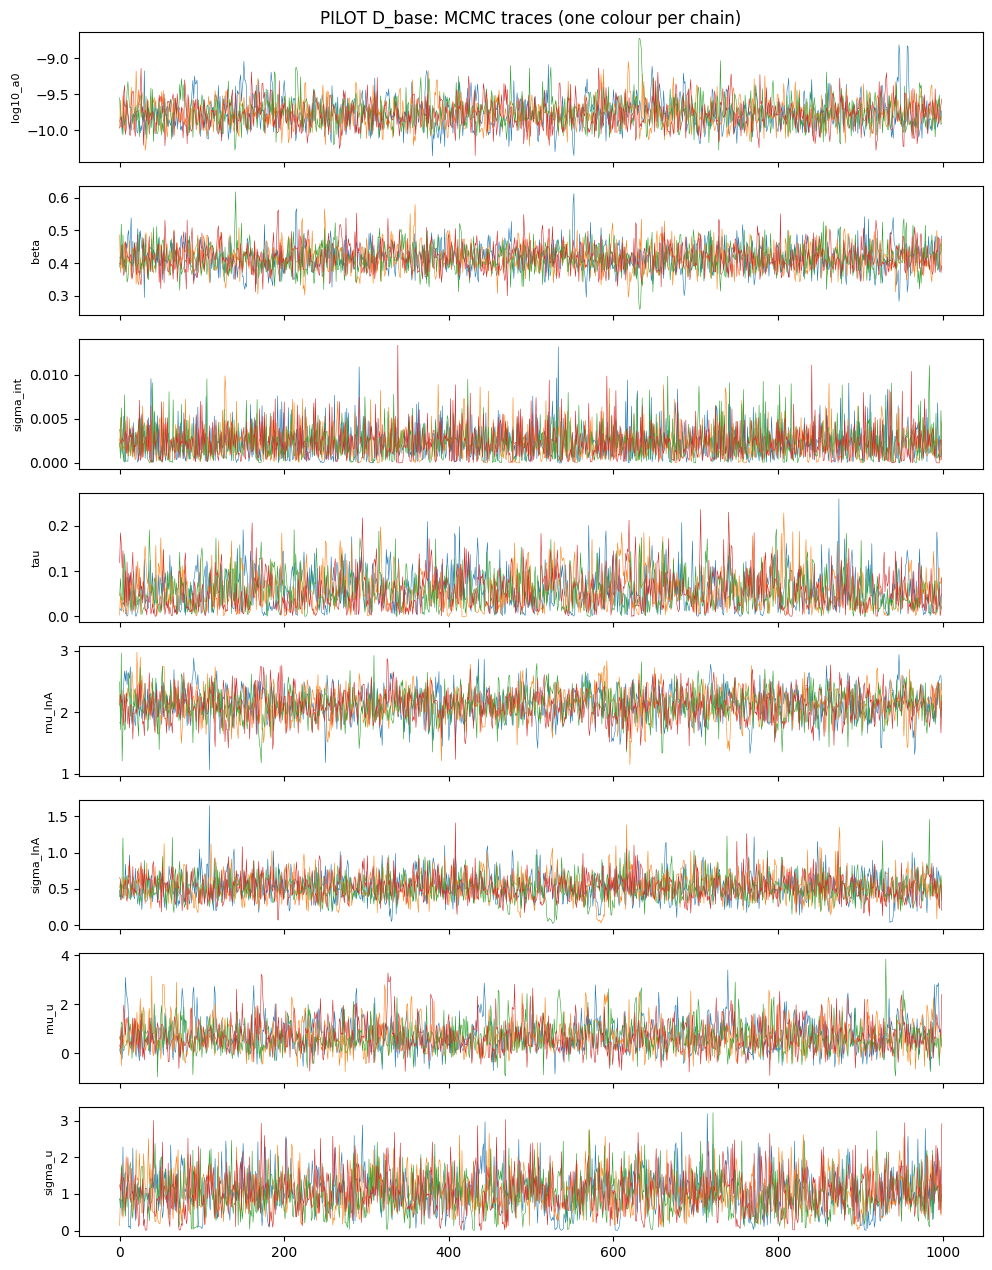

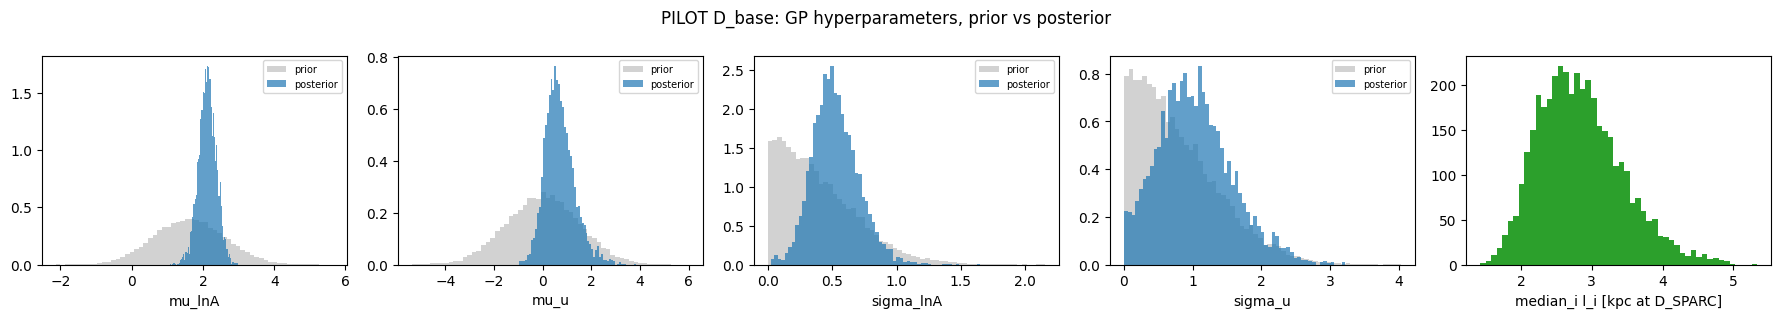

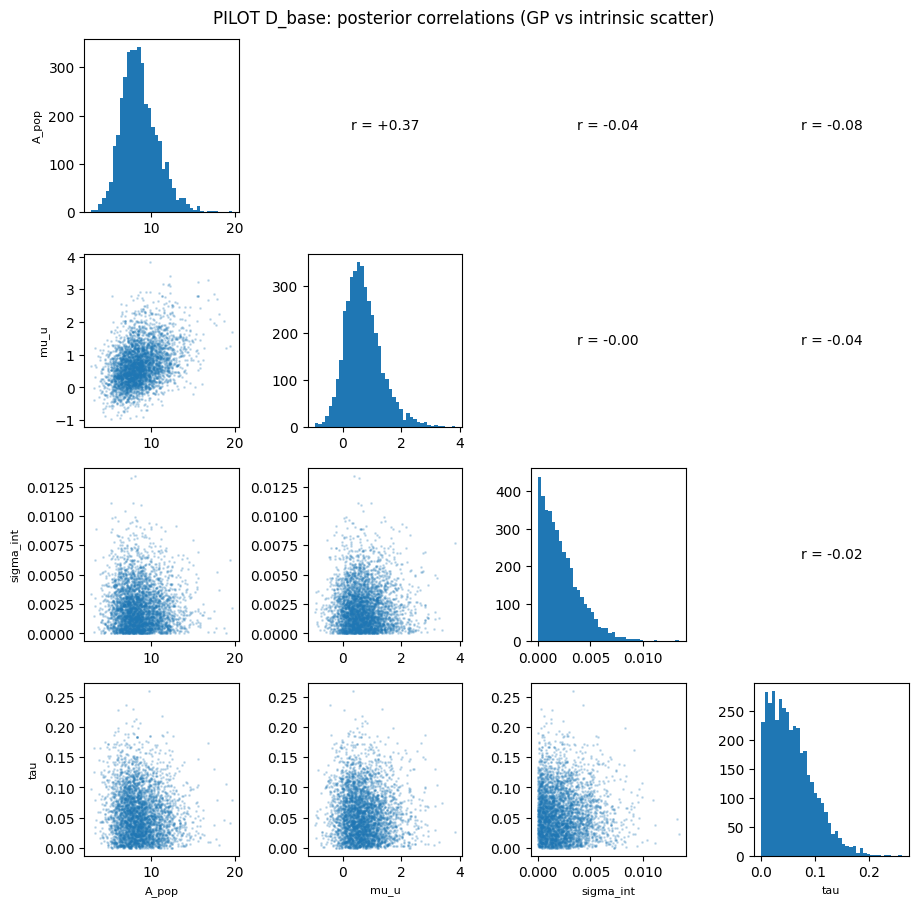

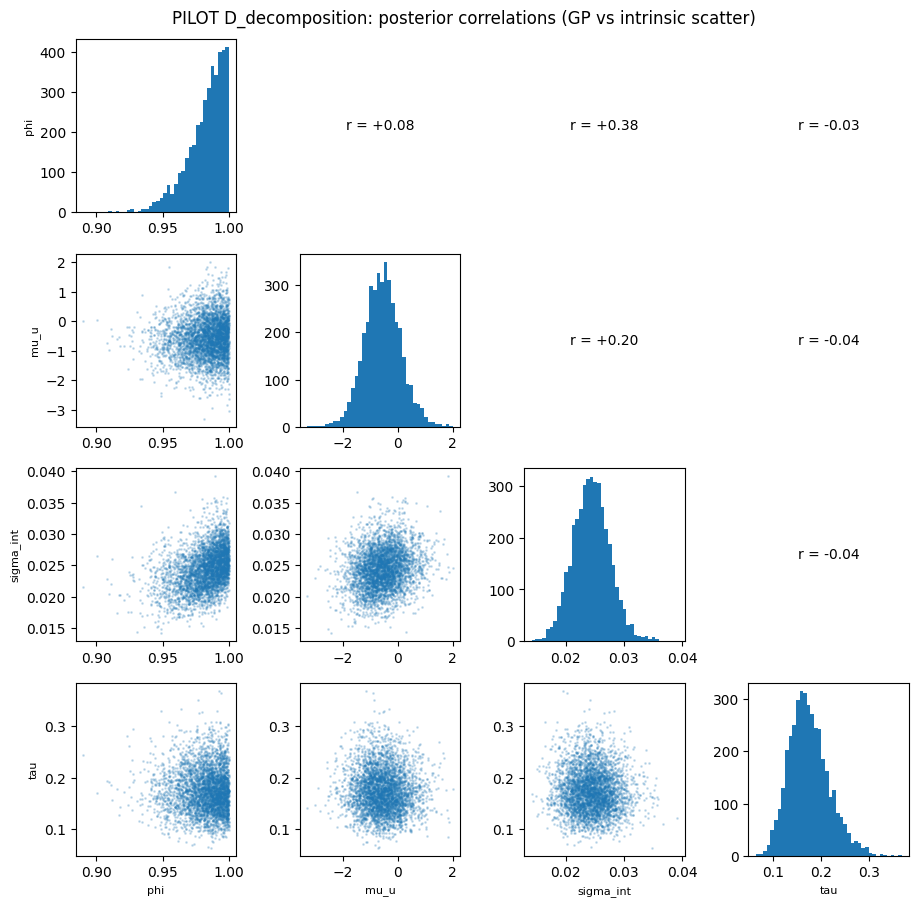

In [16]:
# Pilot figures: traces, GP hyperparameter prior vs posterior, correlations
def fig_traces(res, label, fname):
    smp = res["mcmc"].get_samples(group_by_chain=True)
    ks = [k for k in ("log10_a0", "beta", "sigma_int", "tau", "mu_lnA", "sigma_lnA", "mu_u", "sigma_u", "phi") if k in smp]
    fig, ax = plt.subplots(len(ks), 1, figsize=(10, 1.6 * len(ks)), sharex=True)
    for a, k in zip(np.atleast_1d(ax), ks):
        for c in np.asarray(smp[k]): a.plot(c, lw=0.4)
        a.set_ylabel(k, fontsize=8)
    np.atleast_1d(ax)[0].set_title(f"{label}: MCMC traces (one colour per chain)"); fig.tight_layout()
    out = safe_path(DIRS["graphs"] / fname); fig.savefig(out, dpi=130); plt.show(); return out

def fig_gp_prior_post(res, label, fname):
    smp = res["mcmc"].get_samples(); rng_ = np.random.default_rng(3); n = 20000
    pri = {"mu_lnA": rng_.normal(GP_PRIORS["mu_lnA"]["loc"], GP_PRIORS["mu_lnA"]["scale"], n), "mu_u": rng_.normal(0, GP_PRIORS["mu_u"]["scale"], n),
           "sigma_lnA": np.abs(rng_.normal(0, GP_PRIORS["sigma_lnA"]["scale"], n)), "sigma_u": np.abs(rng_.normal(0, GP_PRIORS["sigma_u"]["scale"], n)),
           "phi": rng_.uniform(0, 1, n)}
    ks = [k for k in pri if k in smp]
    fig, ax = plt.subplots(1, len(ks) + 1, figsize=(3.6 * (len(ks) + 1), 3.2))
    for a, k in zip(ax, ks):
        a.hist(pri[k], bins=60, density=True, alpha=0.35, color="gray", label="prior"); a.hist(np.asarray(smp[k]), bins=60, density=True, alpha=0.7, label="posterior")
        a.set_xlabel(k); a.legend(fontsize=7)
    a = ax[-1]; a.hist(np.median(np.asarray(smp["ell"]), axis=1), bins=50, color="C2"); a.set_xlabel("median_i l_i [kpc at D_SPARC]")
    fig.suptitle(f"{label}: GP hyperparameters, prior vs posterior"); fig.tight_layout()
    out = safe_path(DIRS["graphs"] / fname); fig.savefig(out, dpi=130); plt.show(); return out

def fig_pairs(res, label, fname):
    smp = res["mcmc"].get_samples()
    ks = [k for k in ("A_pop", "phi", "mu_u", "sigma_int", "tau") if k in smp]
    M = np.column_stack([np.asarray(smp[k]) for k in ks]); n = len(ks)
    fig, ax = plt.subplots(n, n, figsize=(2.3 * n, 2.3 * n))
    for i in range(n):
        for j in range(n):
            a = ax[i, j]
            if i == j: a.hist(M[:, i], bins=40)
            elif i > j: a.scatter(M[:, j], M[:, i], s=1, alpha=0.2)
            else: a.text(0.5, 0.5, f"r = {np.corrcoef(M[:, i], M[:, j])[0, 1]:+.2f}", ha="center", va="center"); a.set_axis_off()
            if j == 0: a.set_ylabel(ks[i], fontsize=8)
            if i == n - 1: a.set_xlabel(ks[j], fontsize=8)
    fig.suptitle(f"{label}: posterior correlations (GP vs intrinsic scatter)"); fig.tight_layout()
    out = safe_path(DIRS["graphs"] / fname); fig.savefig(out, dpi=120); plt.show(); return out

if "mcmc" in base:
    fig_traces(base, "PILOT D_base", "04_gp_pilot_D_base_traces.png")
    fig_gp_prior_post(base, "PILOT D_base", "04_gp_pilot_D_base_gp_prior_vs_posterior.png")
    fig_pairs(base, "PILOT D_base", "04_gp_pilot_D_base_pair_correlations.png")
if "mcmc" in PILOT_RESULTS.get("D_decomposition", {}):
    fig_pairs(PILOT_RESULTS["D_decomposition"], "PILOT D_decomposition", "04_gp_pilot_D_decomposition_pair_correlations.png")

## 14. Full Model D Inference — Explicit Opt-In

Run this **only after** PILOT D_base meets all criteria. The benchmark below times one likelihood-plus-gradient evaluation on the full data and multiplies it by the pilot's average number of leapfrog steps to give a rough runtime estimate. Each model is saved **as soon as it completes**. Interrupted chains cannot be resumed.

In [17]:
# ---- Benchmark (recorded; no fitting) ----
cfgD = variant_cfg("D")
iv = init_values(data_full, cfgD)
from numpyro.infer.util import log_density
lp_grad = jax.jit(jax.value_and_grad(lambda p: log_density(rar_gp_model, (data_full, cfgD), {}, p)[0]))
t0 = time.time(); val, gr = lp_grad(iv); jax.block_until_ready(val); t_compile = time.time() - t0
t0 = time.time(); [jax.block_until_ready(lp_grad(iv)[0]) for _ in range(5)]; t_eval = (time.time() - t0) / 5
steps = base.get("stats", {}).get("mean_num_steps", np.nan)
est_hours = t_eval * steps * (FULL["warmup"] + FULL["samples"]) * FULL["chains"] / 3600 if np.isfinite(steps) else np.nan
mem_mb = sum(int(b["gal"].shape[0]) * b["Nb"] ** 2 * 8 for b in data_full["buckets"]) / 1e6
BENCH = {"device": jax.default_backend(), "log_density_finite": bool(np.isfinite(float(val))), "compile_seconds": t_compile,
         "seconds_per_grad_eval": t_eval, "pilot_mean_leapfrog_steps": steps, "estimated_full_hours_per_model": est_hours,
         "dense_covariance_storage_MB": mem_mb, "peak_rss_MB_so_far": resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024}
record_check("Benchmark", "full-data Model D log-density and gradient finite at initial values",
             BENCH["log_density_finite"] and all(bool(jnp.all(jnp.isfinite(v))) for v in jax.tree_util.tree_leaves(gr)), f"log p = {float(val):.2f}")
print(json.dumps(BENCH, indent=1))
print("The estimate assumes the full posterior needs as many leapfrog steps per iteration as the pilot; it can differ substantially.")

INFO: [PASS] Benchmark | full-data Model D log-density and gradient finite at initial values | log p = 2582.11
{
 "device": "cpu",
 "log_density_finite": true,
 "compile_seconds": 22.29524850845337,
 "seconds_per_grad_eval": 0.07507386207580566,
 "pilot_mean_leapfrog_steps": 31.05475,
 "estimated_full_hours_per_model": 6.476111161940627,
 "dense_covariance_storage_MB": 1.087536,
 "peak_rss_MB_so_far": 2323.17578125
}
The estimate assumes the full posterior needs as many leapfrog steps per iteration as the pilot; it can differ substantially.


In [18]:
# RUN_FULL = True     # <-- uncomment to run full Model D (and Model E, Section 15) on all 153 galaxies
FULL_RESULTS = {}
def run_full_model(name):
    cfg = variant_cfg(name)
    logger.info(f"FULL Model {name}: starting {FULL}")
    try:
        mc, secs, meth, wl = run_mcmc(data_full, cfg, FULL["chains"], FULL["warmup"], FULL["samples"], SEED + (1000 if name == "D" else 2000))
        dg, st = diagnostics(mc)
        FULL_RESULTS[name] = {"cfg": cfg, "data": data_full, "mcmc": mc, "diag": dg, "stats": st, "seconds": secs}   # kept even if saving fails
        llg = loglik_all_draws(mc, data_full, cfg)
        nc = save_netcdf(mc, data_full, DIRS["posterior"] / f"04_gp_full_model_{name}_posterior.nc", llg, {"stage": "FULL", "model": name, "run_id": RUN_ID, **cfg})
        label = f"FULL Model {name}" + ("" if st["converged_by_all_criteria"] else " (NOT CONVERGED)")
        FULL_RESULTS[name] = {"cfg": cfg, "data": data_full, "mcmc": mc, "diag": dg, "stats": st, "seconds": secs, "method": meth, "warnings": wl,
                              "ll_g": llg, "nc": nc, "summary": summarise(mc.get_samples(), label)}
        dg.assign(stage=label).to_csv(safe_path(DIRS["diagnostics"] / f"04_gp_full_model_{name}_mcmc_diagnostics.csv"), index=False)
        logger.info(f"FULL Model {name}: done in {secs/3600:.2f} h; converged_by_all_criteria={st['converged_by_all_criteria']}")
    except Exception as exc:
        logger.error(f"FULL Model {name} FAILED: {exc}"); FULL_RESULTS.setdefault(name, {"cfg": cfg})["error"] = str(exc)

if not RUN_FULL:
    print("FULL Model D NOT run (RUN_FULL = False). No full-sample GP results exist from this session.")
elif not (PILOT_OK or FORCE_FULL_DESPITE_PILOT):
    print("FULL Model D NOT run: PILOT D_base did not meet all criteria.")
else:
    if not PILOT_OK: logger.warning("FULL run forced although the pilot did not meet all criteria; this must be reported.")
    run_full_model("D")

FULL Model D NOT run (RUN_FULL = False). No full-sample GP results exist from this session.


## 15. Full Model E Prior Sensitivity Analysis — Explicit Opt-In

Model E is identical to Model D except for the Υ★ prior width (0.2 dex instead of 0.1 dex, disk and bulge). It uses the same data, likelihood, GP block and all other priors. It runs only if `RUN_FULL` is True and the pilot passed.

In [19]:
if RUN_FULL and (PILOT_OK or FORCE_FULL_DESPITE_PILOT) and "E" in FULL["models"]:
    run_full_model("E")
else:
    print("FULL Model E NOT run.")

FULL Model E NOT run.


## 16. Independent Versus Correlated Error Comparison

Model C is read from Notebook 03's saved posterior and is not refitted. The comparison covers posterior medians and intervals, convergence, marginal predictive coverage, whitened-residual autocorrelation, and **integrated galaxy-level LOO** (each galaxy left out together with its own nuisance and GP parameters). The same integrated estimator is applied to C, D and E, so the elpd values are comparable. A reduction in σ_int is stated **only** if D's 95% upper bound lies below C's 95% lower bound.

In [20]:
comp_rows, loo_rows, extra = [], [], {}
sC = nc_samples_flat(NC03["C"], ["log10_a0", "beta", "sigma_int", "tau", "D", "inc", "ups_disk", "ups_bulge"])
sumC = summarise(sC, "NB03 FULL Model C")
models_here = {"C": {"samples": sC, "cfg": None, "stats": CFG03["full"]["completed_models"]["C"]["stats"], "summary": sumC, "ups": UPS_SIGMA_DEX["D"]}}
for m, r in FULL_RESULTS.items():
    if "mcmc" in r:
        models_here[m] = {"samples": {k: np.asarray(v) for k, v in r["mcmc"].get_samples().items()}, "cfg": r["cfg"], "stats": r["stats"],
                          "summary": r["summary"], "ups": r["cfg"]["ups_sig"]}
if len(models_here) == 1:
    print("Only Model C (Notebook 03) is available at full scale; D/E comparisons need the opt-in full runs. Pilot-scale comparison follows.")

def compare_block(models, data, scale_label):
    rows, loos, cov = [], [], {}
    for m, info in models.items():
        smp = info["samples"]; s = info["summary"].set_index("parameter")
        row = {"scale": scale_label, "model": m, "converged_by_all_criteria": info["stats"]["converged_by_all_criteria"],
               "max_r_hat": info["stats"]["max_r_hat_all"], "min_ess_bulk": info["stats"]["min_ess_bulk_all"], "divergences": info["stats"]["divergences"]}
        for p in ("log10_a0", "beta", "sigma_int", "tau", "A_pop", "phi", "ell_median_kpc"):
            if p in s.index:
                row[f"{p}_median"] = s.loc[p, "median"]; row[f"{p}_ci95"] = f"[{s.loc[p,'ci95_low']:.4f}, {s.loc[p,'ci95_high']:.4f}]"; row[f"{p}_ci95_width"] = s.loc[p, "ci95_width"]
        pw = ppc_and_whitening(iter_draws_from_samples(smp, data, info["cfg"], PPC_DRAWS), data, info["cfg"], jax.random.PRNGKey(SEED))
        row.update({"ppc_coverage68": pw["coverage68"], "ppc_coverage95": pw["coverage95"], "lag1_whitened_median": pw["lag1_whitened_median_over_galaxies"]})
        cov[m] = pw
        N = len(np.asarray(smp["log10_a0"]).ravel()); sel = np.linspace(0, N - 1, min(ILOO["post_draws"], N)).astype(int)
        pop = {k: np.asarray(smp[k]).ravel()[sel] for k in ("log10_a0", "beta", "sigma_int", "tau", "mu_lnA", "sigma_lnA", "mu_u", "sigma_u", "phi") if k in smp}
        if info["cfg"] is not None and info["cfg"]["pooling"] == "complete":
            pop["sigma_lnA"] = np.zeros(len(sel)); pop["sigma_u"] = np.zeros(len(sel))
        ll_int = integrated_loglik(pop, data, info["cfg"], info["ups"], ILOO["mc"], SEED + 7)
        ls, elpd, k = loo_summary(ll_int, f"{scale_label} {m}")
        row.update({"elpd_integrated_loo": ls["elpd_loo"], "elpd_se": ls["elpd_se"], "n_galaxies_k_gt_0.7": ls["n_k_gt_0.7"]})
        loos.append(pd.DataFrame({"model": m, "galaxy": gtab.galaxy.to_numpy()[data["gal_ids"]], "elpd_i": elpd, "pareto_k": k}))
        rows.append(row)
    df = pd.DataFrame(rows)
    if "C" in df.model.values:
        c = df[df.model == "C"].iloc[0]
        for i, r in df.iterrows():
            for p in ("sigma_int", "tau", "log10_a0", "beta"):
                df.loc[i, f"delta_{p}_median_vs_C"] = r[f"{p}_median"] - c[f"{p}_median"]
                df.loc[i, f"ci95_width_ratio_{p}_vs_C"] = r[f"{p}_ci95_width"] / c[f"{p}_ci95_width"]
            df.loc[i, "delta_elpd_vs_C"] = r["elpd_integrated_loo"] - c["elpd_integrated_loo"]
    return df, (pd.concat(loos) if loos else pd.DataFrame()), cov

full_comp, full_loo, full_cov = compare_block(models_here, data_full, "FULL") if len(models_here) > 1 else (pd.DataFrame(), pd.DataFrame(), {})

# Pilot-scale comparison (NB03 pilot Model C vs pilot D_base / E_base) — validation only
data_pilot = build_data(include_mask, pilot_gals)
pilot_models = {}
if nc03_pilot.is_file():
    s03p_full = nc_samples_flat(nc03_pilot, ["log10_a0", "beta", "sigma_int", "tau", "D", "inc", "ups_disk", "ups_bulge"])
    pilot_models["C"] = {"samples": s03p_full, "cfg": None, "stats": CFG03["pilot"]["stats"], "summary": summarise(s03p_full, "NB03 PILOT C"), "ups": UPS_SIGMA_DEX["D"]}
for v in ("D_base", "E_base"):
    r = PILOT_RESULTS.get(v, {})
    if "mcmc" in r:
        pilot_models[v] = {"samples": {k: np.asarray(x) for k, x in r["mcmc"].get_samples().items()}, "cfg": r["cfg"], "stats": r["stats"],
                           "summary": r["summary"], "ups": r["cfg"]["ups_sig"]}
pilot_comp, pilot_loo, pilot_cov = compare_block(pilot_models, data_pilot, "PILOT (validation only)") if pilot_models else (pd.DataFrame(), pd.DataFrame(), {})
model_comparison = pd.concat([pilot_comp, full_comp], ignore_index=True)
display(model_comparison)

def reduction_statement(df, scale):
    if df.empty or "C" not in df.model.values: return f"{scale}: comparison not available."
    c = df[df.model == "C"].iloc[0]; out = []
    lo_c = float(c["sigma_int_ci95"].strip("[]").split(",")[0])
    for _, r in df[df.model != "C"].iterrows():
        hi = float(r["sigma_int_ci95"].strip("[]").split(",")[1])
        verdict = "supported (95% intervals separated)" if hi < lo_c else "NOT established (95% intervals overlap or D/E is larger)"
        conv = "" if r["converged_by_all_criteria"] else " [model not converged: do not interpret]"
        out.append(f"{scale} {r['model']}: sigma_int median {r['sigma_int_median']:.4f} vs C {c['sigma_int_median']:.4f}; reduction {verdict}{conv}")
    return "\n".join(out)
REDUCTION_TEXT = reduction_statement(full_comp, "FULL") + "\n" + reduction_statement(pilot_comp, "PILOT")
print(REDUCTION_TEXT)

Only Model C (Notebook 03) is available at full scale; D/E comparisons need the opt-in full runs. Pilot-scale comparison follows.


,scale,model,converged_by_all_criteria,max_r_hat,min_ess_bulk,divergences,log10_a0_median,log10_a0_ci95,log10_a0_ci95_width,beta_median,...,ell_median_kpc_ci95_width,delta_sigma_int_median_vs_C,ci95_width_ratio_sigma_int_vs_C,delta_tau_median_vs_C,ci95_width_ratio_tau_vs_C,delta_log10_a0_median_vs_C,ci95_width_ratio_log10_a0_vs_C,delta_beta_median_vs_C,ci95_width_ratio_beta_vs_C,delta_elpd_vs_C
0,PILOT (validation only),C,True,1.002144,2553.916447,0,-10.271714,"[-10.5062, -9.9704]",0.535785,0.599839,...,NaN,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
1,PILOT (validation only),D_base,False,1.005373,1208.293015,1,-9.772947,"[-10.1096, -9.3353]",0.774257,0.414917,...,2.324062,-0.058512,0.260907,-0.135959,0.957732,0.498767,1.445088,-0.184923,0.885304,141.071627
2,PILOT (validation only),E_base,False,1.004071,923.387172,33,-9.849884,"[-10.2203, -9.3657]",0.854593,0.432326,...,2.551147,-0.058504,0.262234,-0.133191,1.016278,0.421830,1.595029,-0.167513,1.142762,140.602212


FULL: comparison not available.
PILOT D_base: sigma_int median 0.0018 vs C 0.0604; reduction supported (95% intervals separated) [model not converged: do not interpret]
PILOT E_base: sigma_int median 0.0019 vs C 0.0604; reduction supported (95% intervals separated) [model not converged: do not interpret]


## 17. Scientific Figures and Tables

Every figure title states its stage: PILOT or FULL, and NB03 for Model C. Observed data are plotted as points; model predictions are plotted as lines or bands.

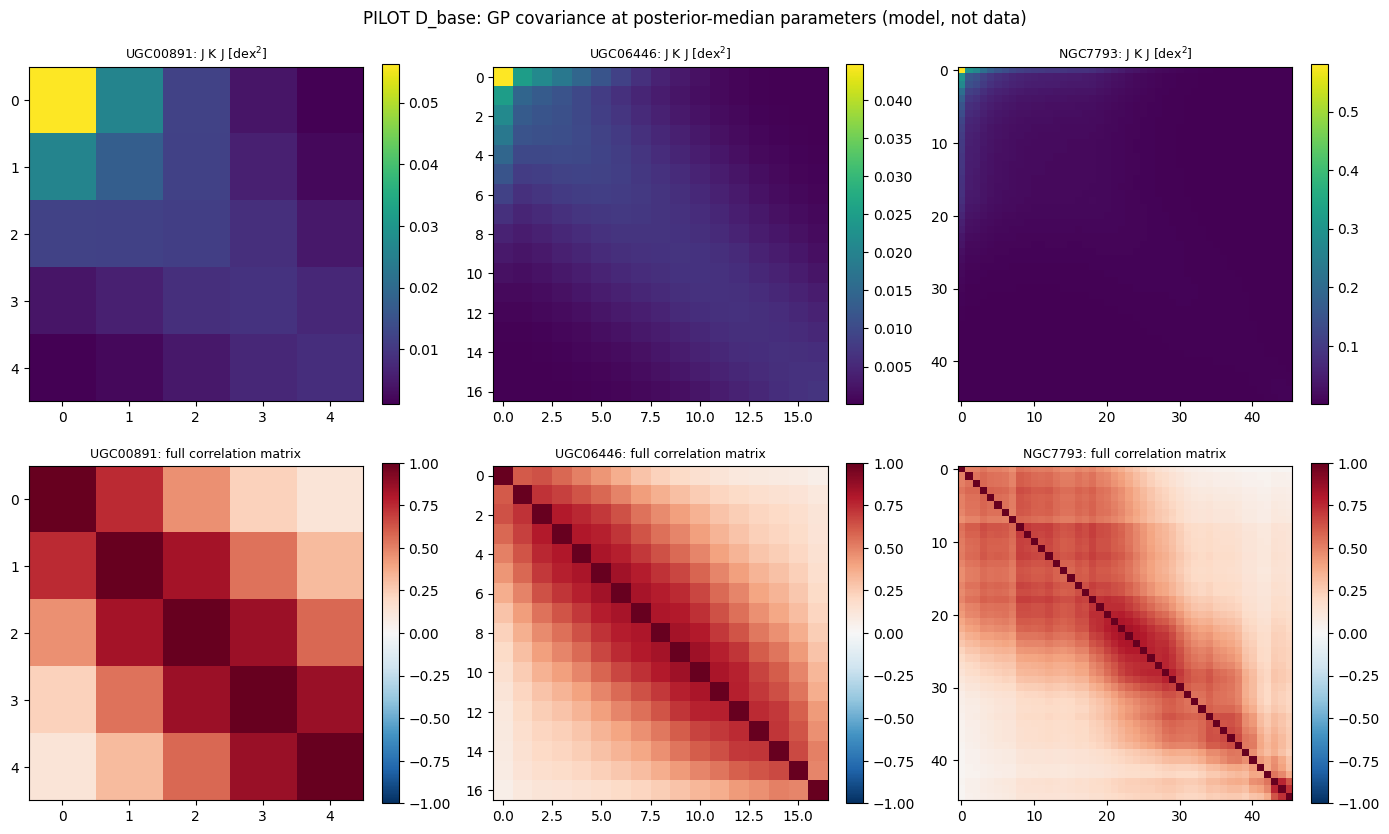

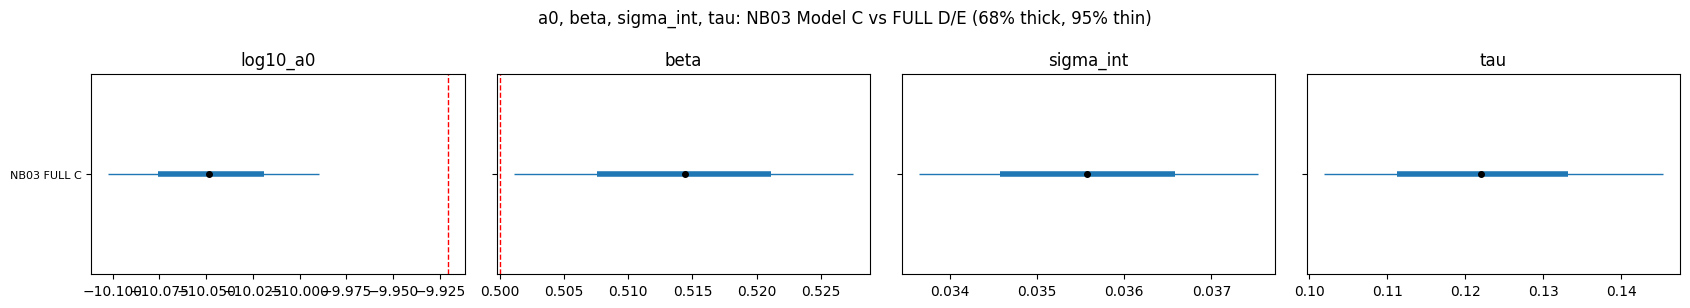

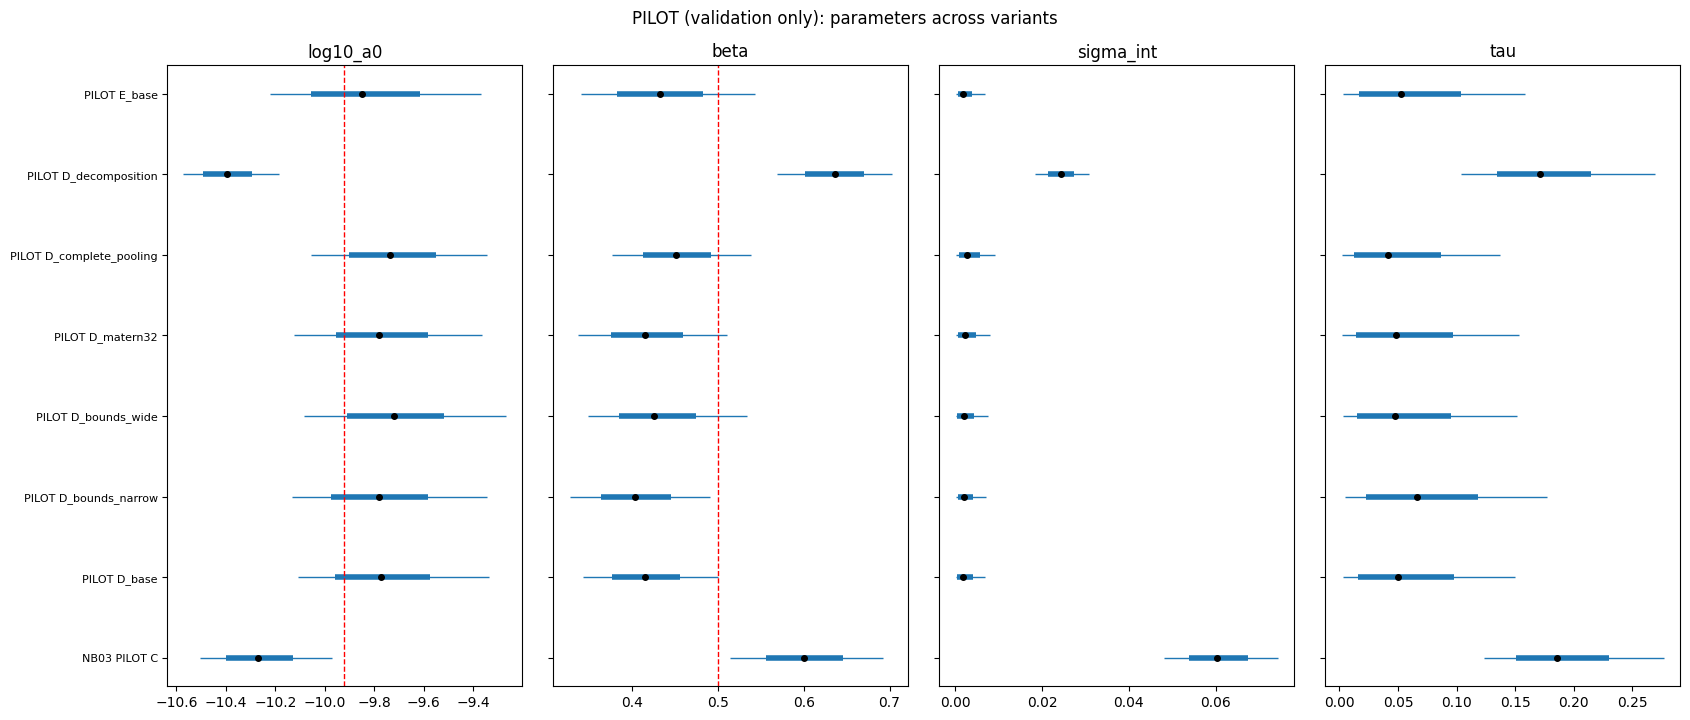

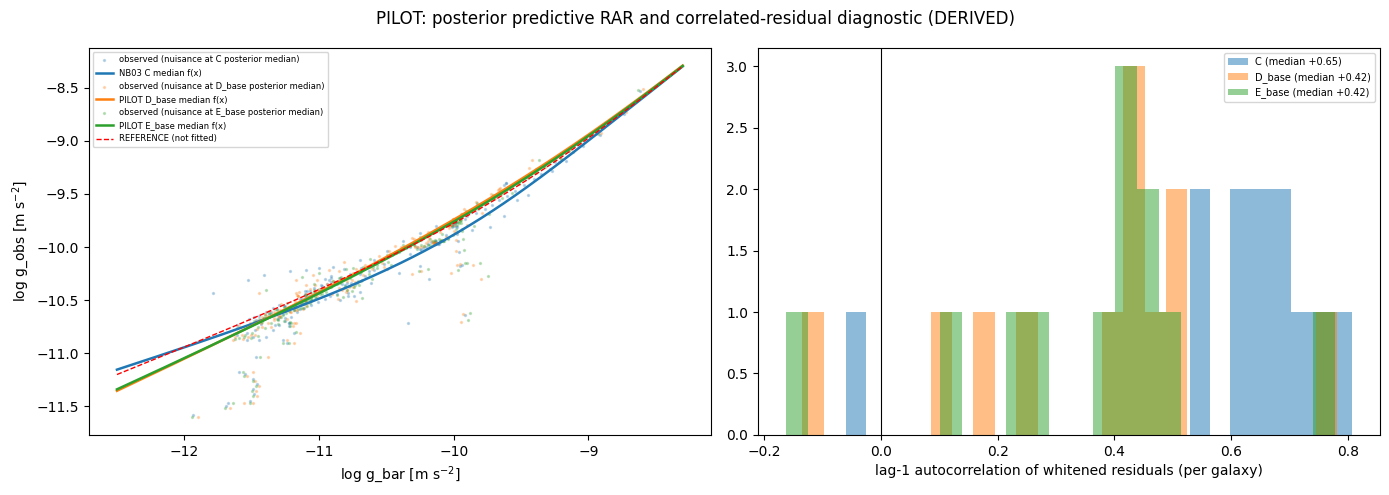

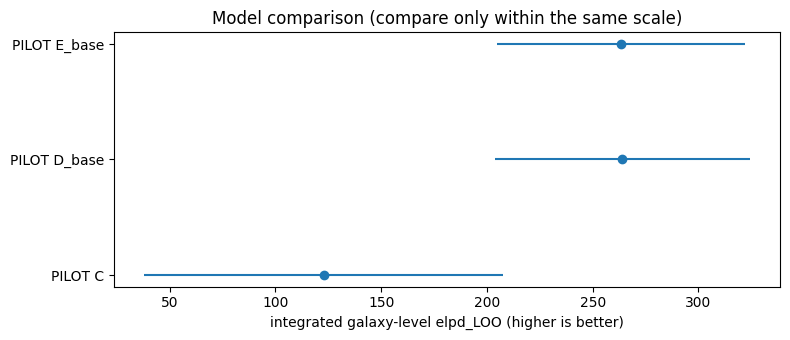

In [21]:
def choose_display(results_full, results_pilot):
    if "D" in results_full and "mcmc" in results_full["D"]: return results_full["D"], "FULL Model D"
    return results_pilot.get("D_base"), "PILOT D_base"
disp, disp_label = choose_display(FULL_RESULTS, PILOT_RESULTS)

# (1) Covariance heatmaps for three representative galaxies (few / median / many points)
if disp and "mcmc" in disp:
    smp = disp["mcmc"].get_samples(); data = disp["data"]; cfg = disp["cfg"]
    med = lambda k: jnp.asarray(np.median(np.asarray(smp[k]), axis=0))
    th = tuple(float(np.median(np.asarray(smp[k]))) for k in ("log10_a0", "beta", "sigma_int", "tau")) + (1.0,)
    ub = jnp.full(data["G"], REF["upsilon_bulge"])
    if data["n_bulge"]: ub = ub.at[data["bulge_local"]].set(med("ups_bulge"))
    nuis = (med("D"), med("inc"), med("ups_disk"), ub)
    gp = {"ell": med("ell"), **({"A": med("A")} if cfg["mode"] == "additive" else {"phi": float(np.median(np.asarray(smp["phi"])))})}
    r, x, y, mu, d_ind, cvec, ell, kind = covariance_parts(th, nuis, gp, data, cfg)
    order = np.argsort(data["npts"]); picks = [order[0], order[len(order) // 2], order[-1]]
    fig, ax = plt.subplots(2, 3, figsize=(14, 8.5))
    for j, g in enumerate(picks):
        b = next(b for b in data["buckets"] if g in np.asarray(b["gal"])); a = int(np.where(np.asarray(b["gal"]) == g)[0][0]); n = int(b["n"][a])
        S = np.asarray(bucket_cov(b, d_ind, cvec, ell, th[3], kind, 0.0))[a, :n, :n]
        JKJ = np.asarray(bucket_cov(b, jnp.zeros_like(d_ind), cvec, ell, 0.0, kind, 0.0))[a, :n, :n]
        name = gtab.galaxy.iloc[data["gal_ids"][g]]
        im = ax[0, j].imshow(JKJ, cmap="viridis"); fig.colorbar(im, ax=ax[0, j], fraction=0.046); ax[0, j].set_title(f"{name}: J K J [dex$^2$]", fontsize=9)
        Cn = S / np.sqrt(np.outer(np.diag(S), np.diag(S)))
        im = ax[1, j].imshow(Cn, cmap="RdBu_r", vmin=-1, vmax=1); fig.colorbar(im, ax=ax[1, j], fraction=0.046); ax[1, j].set_title(f"{name}: full correlation matrix", fontsize=9)
    fig.suptitle(f"{disp_label}: GP covariance at posterior-median parameters (model, not data)"); fig.tight_layout()
    fig.savefig(safe_path(DIRS["graphs"] / "04_gp_covariance_heatmaps.png"), dpi=130); plt.show()

# (4)+(5)+(10) parameter comparison across models
def fig_param_compare(df_list, fname, title):
    rows = []
    for lab, s in df_list:
        for p in ("log10_a0", "beta", "sigma_int", "tau"):
            r = s[s.parameter == p]
            if len(r): rows.append((lab, p, r["median"].iloc[0], r["ci68_low"].iloc[0], r["ci68_high"].iloc[0], r["ci95_low"].iloc[0], r["ci95_high"].iloc[0]))
    if not rows: return
    t = pd.DataFrame(rows, columns=["label", "p", "med", "l68", "h68", "l95", "h95"])
    fig, ax = plt.subplots(1, 4, figsize=(17, 0.6 * t.label.nunique() + 2.5))
    for a, p in zip(ax, ("log10_a0", "beta", "sigma_int", "tau")):
        tt = t[t.p == p].reset_index(drop=True)
        a.hlines(range(len(tt)), tt.l95, tt.h95, color="C0", lw=1); a.hlines(range(len(tt)), tt.l68, tt.h68, color="C0", lw=4); a.plot(tt.med, range(len(tt)), "ko", ms=4)
        a.set_yticks(range(len(tt))); a.set_yticklabels(tt.label if p == "log10_a0" else [""] * len(tt), fontsize=8); a.set_title(p)
        if p == "log10_a0": a.axvline(np.log10(REF["a0"]), color="r", ls="--", lw=1, label="REFERENCE")
        if p == "beta": a.axvline(REF["beta"], color="r", ls="--", lw=1)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(safe_path(DIRS["graphs"] / fname), dpi=130); plt.show()

lst = [("NB03 FULL C", sumC)] + [(f"FULL {m}", r["summary"]) for m, r in FULL_RESULTS.items() if "summary" in r]
fig_param_compare(lst, "04_gp_full_parameter_comparison_C_D_E.png", "a0, beta, sigma_int, tau: NB03 Model C vs FULL D/E (68% thick, 95% thin)")
lstp = ([("NB03 PILOT C", pilot_models["C"]["summary"])] if "C" in pilot_models else []) + [(f"PILOT {v}", r["summary"]) for v, r in PILOT_RESULTS.items() if "summary" in r]
fig_param_compare(lstp, "04_gp_pilot_parameter_comparison.png", "PILOT (validation only): parameters across variants")

# (6)+(7) predictive RAR and correlated-residual diagnostics
cov_src, cov_label = (full_cov, "FULL") if full_cov else (pilot_cov, "PILOT")
if cov_src:
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    lg = np.linspace(-12.5, -8.3, 200)
    for m, pw in cov_src.items():
        ax[0].scatter(pw["x_med"], pw["y_med"], s=2, alpha=0.25, label=f"observed (nuisance at {m} posterior median)")
        info = (models_here if cov_src is full_cov else pilot_models)[m]; smp = info["samples"]
        la0, bb = np.median(np.asarray(smp["log10_a0"])), np.median(np.asarray(smp["beta"]))
        ax[0].plot(lg, np.asarray(f_rar(lg, la0, bb)), lw=1.8, label=(f"NB03 {m}" if m == "C" else f"{cov_label} {m}") + " median f(x)")
        ax[1].hist(pw["lag1_per_galaxy"][np.isfinite(pw["lag1_per_galaxy"])], bins=25, alpha=0.5, label=f"{m} (median {pw['lag1_whitened_median_over_galaxies']:+.2f})")
    ax[0].plot(lg, np.asarray(f_rar(lg, np.log10(REF["a0"]), REF["beta"])), "r--", lw=1, label="REFERENCE (not fitted)")
    ax[0].set_xlabel("log g_bar [m s$^{-2}$]"); ax[0].set_ylabel("log g_obs [m s$^{-2}$]"); ax[0].legend(fontsize=6)
    ax[1].axvline(0, color="k", lw=0.8); ax[1].set_xlabel("lag-1 autocorrelation of whitened residuals (per galaxy)"); ax[1].legend(fontsize=7)
    fig.suptitle(f"{cov_label}: posterior predictive RAR and correlated-residual diagnostic (DERIVED)"); fig.tight_layout()
    fig.savefig(safe_path(DIRS["graphs"] / f"04_gp_{cov_label.lower()}_ppc_and_whitened_residuals.png"), dpi=130); plt.show()

# (10) model comparison summary: integrated elpd
mc_df = model_comparison.dropna(subset=["elpd_integrated_loo"]) if "elpd_integrated_loo" in model_comparison else pd.DataFrame()
if len(mc_df):
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(mc_df) + 2))
    labels = mc_df.scale.str.split(" ").str[0] + " " + mc_df.model
    ax.errorbar(mc_df.elpd_integrated_loo, range(len(mc_df)), xerr=mc_df.elpd_se, fmt="o")
    ax.set_yticks(range(len(mc_df))); ax.set_yticklabels(labels); ax.set_xlabel("integrated galaxy-level elpd_LOO (higher is better)")
    ax.set_title("Model comparison (compare only within the same scale)"); fig.tight_layout()
    fig.savefig(safe_path(DIRS["graphs"] / "04_gp_model_comparison_summary.png"), dpi=130); plt.show()
if "D" in FULL_RESULTS and "mcmc" in FULL_RESULTS["D"]:
    fig_traces(FULL_RESULTS["D"], "FULL Model D", "04_gp_full_model_D_traces.png")
    fig_gp_prior_post(FULL_RESULTS["D"], "FULL Model D", "04_gp_full_model_D_gp_prior_vs_posterior.png")
    fig_pairs(FULL_RESULTS["D"], "FULL Model D", "04_gp_full_model_D_pair_correlations.png")

## 18. Results Export and Reproducibility

In [22]:
diag_all = [r["diag"].assign(stage=f"PILOT {v}") for v, r in PILOT_RESULTS.items() if "diag" in r] + \
           [r["diag"].assign(stage=f"FULL Model {m}") for m, r in FULL_RESULTS.items() if "diag" in r]
pd.concat(diag_all).to_csv(safe_path(DIRS["diagnostics"] / "04_gp_mcmc_diagnostics.csv"), index=False) if diag_all else None
param_all = [r["summary"] for r in PILOT_RESULTS.values() if "summary" in r] + [r["summary"] for r in FULL_RESULTS.values() if "summary" in r] + [sumC.assign(stage="NB03 FULL Model C (read, not refitted)")]
pd.concat(param_all).to_csv(safe_path(DIRS["tables"] / "04_gp_parameter_summary.csv"), index=False)
model_comparison.to_csv(safe_path(DIRS["tables"] / "04_gp_model_comparison.csv"), index=False)
pd.concat([pilot_loo.assign(scale="PILOT"), full_loo.assign(scale="FULL")]).to_csv(safe_path(DIRS["diagnostics"] / "04_gp_integrated_loo_per_galaxy.csv"), index=False)
cov_checks.to_csv(safe_path(DIRS["diagnostics"] / "04_gp_covariance_checks.csv"), index=False)
ident_full = []
for m, r in FULL_RESULTS.items():
    if "mcmc" in r: t, c = identifiability(r, f"FULL Model {m}"); ident_full.append(t)
pd.concat([ident_pilot] + ident_full).to_csv(safe_path(DIRS["diagnostics"] / "04_gp_identifiability_diagnostics.csv"), index=False)
gp_prior_table.to_csv(safe_path(DIRS["tables"] / "04_gp_prior_summary.csv"), index=False)
pd.DataFrame(CHECKS).to_csv(safe_path(DIRS["processed"] / "04_gp_integrity_checks.csv"), index=False)
config = {"run_id": RUN_ID, "created_utc": RUN_TIMESTAMP, "versions": VERSIONS, "seed": SEED, "notebook03_run_id": RUN03,
          "notebook03_posteriors": {m: str(p) for m, p in NC03.items()}, "gp": GP, "bound_variants": BOUND_VARIANTS, "gp_priors": GP_PRIORS,
          "ups_sigma_dex": UPS_SIGMA_DEX, "shared_priors_from_nb03": P03, "target_accept": TARGET_ACCEPT, "max_tree_depth": MAX_TREE_DEPTH,
          "pilot": {**PILOT, "galaxies": pilot_names, "variants": {v: {"cfg": r["cfg"], "seconds": r.get("seconds"), "stats": r.get("stats"), "error": r.get("error"),
                    "netcdf": str(r.get("nc")), "warnings": r.get("warnings", [])[:10]} for v, r in PILOT_RESULTS.items()}},
          "run_full": RUN_FULL, "forced_full": bool(FORCE_FULL_DESPITE_PILOT and not PILOT_OK),
          "full": {**FULL, "completed": {m: {"seconds": r.get("seconds"), "stats": r.get("stats"), "netcdf": str(r.get("nc")), "error": r.get("error")} for m, r in FULL_RESULTS.items()}},
          "convergence_criteria": {"rank_r_hat_max": RHAT_MAX, "ess_bulk_min": ESS_BULK_MIN, "ess_tail_min": ESS_TAIL_MIN, "divergences_max": DIVERGENCES_MAX},
          "integrated_loo": ILOO, "ppc_draws": PPC_DRAWS, "benchmark": BENCH, "regression_test": regression,
          "data_checksums": {NB02[k].name: sha256_of(NB02[k]) for k in NB02}, "n_points": int(include_mask.sum()), "n_galaxies": G,
          "beam_sizes": "not available for SPARC in the project files; correlation-length bounds use radial spacing and extent only",
          "resume_note": "No sampler-state checkpointing; interrupted chains cannot be resumed."}
(safe_path(DIRS["models"] / "04_gp_sampler_config.json")).write_text(json.dumps(config, indent=2, default=str))
print("Exports written.")

Exports written.


## 19. Final Notebook 04 Summary

In [23]:
chk = pd.DataFrame(CHECKS)
def ptab(s):
    keep = s[s.parameter.isin(["log10_a0", "beta", "sigma_int", "tau", "A_pop", "phi", "ell_median_kpc"])]
    return "\n".join(f"| {r.parameter} | {r.median:.4f} | [{r.ci68_low:.4f}, {r.ci68_high:.4f}] | [{r.ci95_low:.4f}, {r.ci95_high:.4f}] |" for r in keep.itertuples())
pilot_lines = "\n".join(f"* {v}: " + (f"error: {r['error']}" if "error" in r else f"converged={r['stats']['converged_by_all_criteria']}, "
                        f"max R-hat {r['stats']['max_r_hat_all']:.4f}, min ESS bulk/tail {r['stats']['min_ess_bulk_all']:.0f}/{r['stats']['min_ess_tail_all']:.0f}, "
                        f"divergences {r['stats']['divergences']}, {r['seconds']/60:.1f} min") for v, r in PILOT_RESULTS.items())
full_lines = "\n\n".join(f"### FULL Model {m} — " + ("FAILED: " + r["error"] if "error" in r else
                          ("converged by all criteria" if r["stats"]["converged_by_all_criteria"] else "NOT CONVERGED: do not interpret")
                          + f"\n\n| parameter | median | 68% | 95% |\n|---|---|---|---|\n{ptab(r['summary'])}") for m, r in FULL_RESULTS.items()) or \
             "**Full Models D and E were not run in this session; no full-sample GP results exist.**"
report = f'''# Notebook 04 — GP Correlated Errors Report

*Run {RUN_ID} ({RUN_TIMESTAMP} UTC); builds on Notebook 03 run {RUN03}. This file exists only if the notebook ran.*

## Verified inputs
* 153 SPARC galaxies, {int(include_mask.sum())} likelihood points, identical to Notebook 03 (positivity rule reproduced; 4 documented exclusions).
* Regression test: zero-GP likelihood vs Notebook 03 saved Model C log-likelihoods: max |diff| = {regression["max_abs_diff_vs_saved_NB03"]:.2e} (10 draws, 153 galaxies).
* Covariance: {len(cov_checks)} matrices checked at extreme hyperparameters; all positive-definite without jitter: {bool(cov_checks.C_pos_def.all())}.
* Beam sizes are not available for SPARC; correlation-length bounds use radial spacing and extent only.

## PILOT (validation only)
{pilot_lines}

## FULL
{full_lines}

## Intrinsic scatter: independent vs correlated errors
{REDUCTION_TEXT}

## Identifiability flags (preliminary; formal test in Notebook 06)
{"; ".join(f"{r.stage}: {r.value}" for r in pd.concat([ident_pilot] + ident_full).query("quantity == 'non_identifiability_flags'").itertuples())}

## Notes
* Model C values are read from Notebook 03 (not refitted). Notebook 03's plain galaxy-level PSIS-LOO had many Pareto k > 0.7 for Model C; this notebook uses integrated galaxy-level LOO for C, D and E.
* Benchmark: {BENCH["seconds_per_grad_eval"]*1000:.1f} ms per full-data gradient on {BENCH["device"]}; estimated {BENCH["estimated_full_hours_per_model"]:.2f} h per full model (rough).

## Checks
{len(chk)} checks: {int((chk.status=="FAIL").sum())} FAIL, {int((chk.status=="WARN").sum())} WARN.
'''
rep = safe_path(DIRS["tables"] / "04_GP_Correlated_Errors_Report.md"); rep.write_text(report, encoding="utf-8")
print("=" * 72); print("NOTEBOOK 04 SUMMARY"); print("=" * 72)
print(f"Sample: {G} galaxies, {int(include_mask.sum())} points (Notebook 03 run {RUN03})")
print(f"Regression (zero-GP vs NB03 saved Model C): max |diff| {regression['max_abs_diff_vs_saved_NB03']:.2e}")
print(pilot_lines)
print("FULL:", {m: ("FAILED" if "error" in r else r["stats"]["converged_by_all_criteria"]) for m, r in FULL_RESULTS.items()} or "not run")
print(REDUCTION_TEXT)
print(f"Checks: {len(chk)} | FAIL {int((chk.status=='FAIL').sum())} | WARN {int((chk.status=='WARN').sum())}")
print("Report:", rep); print("Log:", LOG_PATH)

NOTEBOOK 04 SUMMARY
Sample: 153 galaxies, 3164 points (Notebook 03 run 20261022T095735Z)
Regression (zero-GP vs NB03 saved Model C): max |diff| 1.18e-12
* D_base: converged=False, max R-hat 1.0054, min ESS bulk/tail 1208/1200, divergences 1, 10.6 min
* D_bounds_narrow: converged=False, max R-hat 1.0036, min ESS bulk/tail 929/1179, divergences 9, 8.9 min
* D_bounds_wide: converged=False, max R-hat 1.0058, min ESS bulk/tail 450/626, divergences 2, 10.4 min
* D_matern32: converged=False, max R-hat 1.0052, min ESS bulk/tail 1786/1531, divergences 4, 9.0 min
* D_complete_pooling: converged=True, max R-hat 1.0056, min ESS bulk/tail 1806/1669, divergences 0, 8.2 min
* D_decomposition: converged=True, max R-hat 1.0046, min ESS bulk/tail 1493/1224, divergences 0, 7.1 min
* E_base: converged=False, max R-hat 1.0041, min ESS bulk/tail 923/850, divergences 33, 9.6 min
FULL: not run
FULL: comparison not available.
PILOT D_base: sigma_int median 0.0018 vs C 0.0604; reduction supported (95% intervals